# Aprendizado de Máquina Supervisionado: regressão e suas métricas

A regressão no aprendizado de máquina é uma técnica utilizada para prever resultados contínuos. Em termos simples, é como encontrar a linha que melhor se ajusta a um gráfico de dispersão de pontos de dados. Essa linha pode, então, ser usada para prever valores futuros. Por exemplo, se você quiser prever o consumo de combustível de um carro (como a autonomia em milhas por galão — MPG) com base em características como peso, potência e cilindrada, poderia utilizar a regressão. Você plotaria a média de MPG de cada carro de acordo com suas características e, em seguida, usaria a regressão para identificar a relação entre o MPG e esses atributos. Essa relação pode então ser utilizada para prever o MPG de outros carros com base em suas respectivas características.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import OrdinalEncoder
from sklearn import set_config
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsRegressor
from sklearn.datasets import make_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression, RFECV, SelectFromModel
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [3]:
house_regess = pd.read_csv(r"C:\Users\Helene\OneDrive\Documentos\FAAP\ML_supervisionado\Aula_5/housing_iteration_6_regression.csv")

pd.set_option('display.max_columns', None)

house_regess.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
house_regess.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
house_regess.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
house_regess.shape

(1460, 81)

In [7]:
# Criar X e y 
x = house_regess
y = x.pop("SalePrice")

# Dividir base de dados
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=123)

In [8]:
# Estatística Descritiva
print(x_train.describe())  # Estatísticas das variáveis numéricas
print(x_train.describe(include=['O']))  # Estatísticas das variáveis categóricas


# Análise de Correlação para variáveis numéricas
# Calcula a correlação entre as variáveis numéricas.
# correlation_matrix = x_train.select_dtypes(
#    include=['int64', 'float64']
#).corr()

# Exibe a matriz de correlação em um mapa de calor.
# sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm')
# plt.show()


# Criação de histogramas para todas as variáveis numéricas
# Seleciona apenas as colunas numéricas.
# numerical_columns = x_train.select_dtypes(
#    include=['int64', 'float64']
#).columns

# Cria um histograma para cada variável numérica.
#for column in numerical_columns:
#    plt.figure(figsize=(4, 2))
#    x_train[column].hist(bins=15)
#    plt.title(column)
#    plt.show()

                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1168.000000  1168.000000   979.000000    1168.000000  1168.000000   
mean    730.679795    56.849315    69.584270   10353.034247     6.093322   
std     423.244159    42.462802    23.205003    9411.800862     1.402296   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     367.750000    20.000000    59.000000    7538.750000     5.000000   
50%     724.000000    50.000000    69.000000    9452.500000     6.000000   
75%    1098.250000    70.000000    80.000000   11604.000000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  \
count  1168.000000  1168.000000   1168.000000  1164.000000  1168.000000   
mean      5.583904  1970.898973   1985.007705   103.324742   447.009418   
std       1.129862    30.397482     20.538695   178.429793   465.733256   
min       1.000

In [9]:
# Análise de Correlação para variáveis numéricas
# Calcula a correlação entre as variáveis numéricas.
# correlation_matrix = x_train.select_dtypes(
#    include=['int64', 'float64']
#).corr()

# Exibe a matriz de correlação em um mapa de calor.
#sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm')
# plt.show()

In [10]:
# Atualiza o scikit-learn para uma versão mais recente.
# Isso é necessário porque o Google Colab pode iniciar com uma versão antiga que não possui o método .set_output().
!pip install scikit-learn --upgrade

# IMPORTANTE:
# Execute esta célula novamente sempre que iniciar um novo runtime.
# Se estiver executando o notebook novamente no mesmo runtime, não é necessário instalar o pacote outra vez.

## Pipeline e pré-processamento

### SimpleImputer → Preenche valores ausentes (NaN) no conjunto de dados. Por exemplo, pode substituir um valor ausente pela média da variável numérica ou por uma categoria como "N_A".
### OneHotEncoder → Converte variáveis categóricas em variáveis numéricas (0 e 1), criando uma coluna para cada categoria. É necessário porque muitos algoritmos de Machine Learning trabalham com números.
### ColumnTransformer → Permite aplicar diferentes transformações a diferentes colunas. Por exemplo, podemos padronizar as variáveis numéricas e, ao mesmo tempo, aplicar One-Hot Encoding às variáveis categóricas.

In [13]:
# Separa as variáveis categóricas e numéricas do conjunto de dados.
x_cat_columns = x.select_dtypes(exclude="number").columns
x_num_columns = x.select_dtypes(include="number").columns


# Pipeline para variáveis numéricas:
# 1. Preenche valores ausentes pela média.
# 2. Padroniza os dados para média 0 e desvio-padrão 1.
numeric_pipe = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler()
)


# Pipeline para variáveis categóricas:
# 1. Preenche valores ausentes com "N_A".
# 2. Converte categorias em variáveis numéricas com One-Hot Encoding.
categoric_pipe = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="N_A"),
    OneHotEncoder(sparse_output=False, handle_unknown="ignore")
)


# Cria o pré-processador para aplicar as transformações
# adequadas às variáveis numéricas e categóricas.
preprocessor = ColumnTransformer(
    transformers=[
        ("num_pipe", numeric_pipe, x_num_columns),
        ("cat_pipe", categoric_pipe, x_cat_columns)
    ]
)


# Ajusta o pré-processador apenas com os dados de treinamento e transforma as variáveis de treinamento.
x_train_var = preprocessor.fit_transform(x_train)


# Aplica ao conjunto de teste as mesmas transformações aprendidas com os dados de treinamento.
x_test_var = preprocessor.transform(x_test)

## Regressão Linear

**Para que serve?**
É utilizada para **prever valores numéricos contínuos** e analisar a relação entre uma variável-alvo e uma ou mais variáveis explicativas.

**Como funciona?**

1. Identifica a relação entre as variáveis de entrada e a variável-alvo.
2. Ajusta uma **reta** que representa a melhor relação possível entre os dados.
3. Estima os coeficientes que minimizam a diferença entre os valores observados e previstos.
4. Utiliza a equação ajustada para realizar novas previsões.

**Exemplo:**
Prever o **preço de um imóvel** com base em sua área, número de quartos e localização.

> **Ideia central:** encontrar uma relação matemática que melhor represente os dados e utilizá-la para explicar e prever a variável-alvo.


In [15]:
# Cria um pipeline completo para o modelo de Regressão Linear.
# O pipeline primeiro aplica o pré-processamento das variáveis e, em seguida, treina o modelo de Regressão Linear.
full_pipeline_linear = make_pipeline(
    preprocessor,
    LinearRegression()
)


# Cria o mesmo pipeline, mas com .set_output(transform='pandas').
# Isso faz com que as transformações do pré-processamento sejam retornadas como um DataFrame do pandas, facilitando a visualização e a análise das variáveis transformadas.
pipeline_LinearRegression = make_pipeline(
    preprocessor,
    LinearRegression()
).set_output(transform='pandas')

In [16]:
# Ajustando o pipeline aos dados de treinamento
pipeline_LinearRegression.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throug

In [17]:
# Utiliza o pipeline para gerar as previsões do modelo de Regressão Linear para os dados de treinamento (x_train).
# O pipeline aplica primeiro o pré-processamento e, depois, realiza a previsão.
pipeline_LinearRegression.predict(x_train)

array([322132.56693258, 188475.18631205, 274185.85539052, ...,
       269251.48676842, 137329.54980427, 130502.63314129])

In [18]:
# Define os parâmetros que serão testados pelo GridSearchCV.
# Serão comparadas diferentes formas de preencher valores ausentes e diferentes configurações da Regressão Linear.
param_grid_linear = {
    # Para valores ausentes nas variáveis numéricas:
    # testa média ("mean") e mediana ("median").
    "columntransformer__num_pipe__simpleimputer__strategy": ["mean", "median"],

    # Testa o modelo com e sem intercepto.
    "linearregression__fit_intercept": [True, False]
}


# Cria a busca pelos melhores parâmetros (Grid Search).
# O GridSearchCV testa todas as combinações possíveis dos parâmetros.
search_linear = GridSearchCV(
    full_pipeline_linear,
    param_grid_linear,     # Divide os dados em 5 partes para realizar validação cruzada.
    cv=5,     # Exibe informações sobre o andamento da busca.
    verbose=1,      # Interrompe a execução caso ocorra algum erro.
    error_score='raise'
)


# Treina o GridSearchCV utilizando os dados de treinamento.
# O algoritmo testa todas as combinações de parâmetros e identifica a configuração com melhor desempenho.
search_linear.fit(x_train, y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'columntransformer__num...simpleimputer__strategy': ['mean', 'median'], 'linearregression__fit_intercept': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` i

In [19]:
# Exibe os melhores parâmetros encontrados durante a busca.
# best_params_ retorna a combinação de parâmetros que apresentou o melhor desempenho na validação cruzada.
print("Melhores parâmetros encontrados:")
print(search_linear.best_params_)

Melhores parâmetros encontrados:
{'columntransformer__num_pipe__simpleimputer__strategy': 'median', 'linearregression__fit_intercept': True}


In [20]:
# Retorna o melhor modelo encontrado pelo GridSearchCV, já configurado com os melhores parâmetros identificados.
search_linear.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throug

## Regressão de Árvore de Decisões (Decision Tree Regressor)

**Para que serve?**
É utilizada para **prever valores numéricos contínuos**, dividindo os dados em grupos com características semelhantes.

**Como funciona?**

1. Seleciona uma variável e um **ponto de corte** para dividir os dados.
2. Repete o processo criando novos **nós e ramificações**.
3. Continua dividindo os dados até atingir um critério de parada.
4. Em cada **folha**, calcula o valor médio da variável-alvo das observações daquele grupo.
5. Utiliza esse valor como a previsão para novas observações que chegam àquela folha.

**Exemplo:**
Uma árvore pode separar imóveis por **área ≤ 80 m²** e depois por **número de quartos**, até chegar a grupos com preços semelhantes.

> **Ideia central:** transformar relações complexas em uma sequência de decisões que divide os dados em grupos e atribui a cada grupo uma previsão.

**Importante:** árvores não exigem que as variáveis estejam em escalas semelhantes, pois trabalham com **pontos de corte**.


In [22]:
# Criando o pipeline completo
full_pipeline_tree = make_pipeline(
    preprocessor,
    DecisionTreeRegressor()
)

# Cria o mesmo pipeline, mas com .set_output(transform='pandas')
pipeline_Decisiontreeregression = make_pipeline(
    preprocessor,
    DecisionTreeRegressor()
).set_output(transform='pandas')

# Ajustando o pipeline aos dados de treinamento
pipeline_Decisiontreeregression.fit(x_train, y_train)


# Criando a grade de parâmetros para o GridSearchCV
param_grid = {
    "columntransformer__num_pipe__simpleimputer__strategy": ["mean", "median"],
    "decisiontreeregressor__max_depth": range(2, 14),
    "decisiontreeregressor__min_samples_leaf": range(3, 10),
    "decisiontreeregressor__criterion": [
        'squared_error',
        'poisson'
    ],
    "decisiontreeregressor__splitter": [
        "best",
        "random"
    ]
}


# Criando a busca em grade — definição do GridSearchCV
search_tree = GridSearchCV(
    full_pipeline_tree,
    param_grid,
    cv=5,
    verbose=1,
    error_score='raise'
)

# Executando o GridSearchCV nos dados de treinamento
search_tree.fit(x_train, y_train)


# Imprimindo os melhores parâmetros encontrados pelo GridSearchCV
print("Melhores parâmetros encontrados pelo GridSearchCV:")
print(search_tree.best_params_)


# Visualizando o melhor estimador encontrado
search_tree.best_estimator_

Fitting 5 folds for each of 672 candidates, totalling 3360 fits
Melhores parâmetros encontrados pelo GridSearchCV:
{'columntransformer__num_pipe__simpleimputer__strategy': 'median', 'decisiontreeregressor__criterion': 'poisson', 'decisiontreeregressor__max_depth': 12, 'decisiontreeregressor__min_samples_leaf': 9, 'decisiontreeregressor__splitter': 'best'}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

### OUTRA FORMA DE FAZER

In [24]:
# ============================================================
# Cria um pipeline completo para o modelo de Árvore de Decisões
# ============================================================

# full_pipeline_tree = make_pipeline(
  #  preprocessor,
   # DecisionTreeRegressor()
#)


# ============================================================
# Create the parameter grid for GridSearchCV
# ============================================================

#param_grid = {
 #   "columntransformer__num_pipe__simpleimputer__strategy": [
  #      "mean",
   #     "median"
    #],

    #"decisiontreeregressor__max_depth": range(2, 14),

    #"decisiontreeregressor__min_samples_leaf": range(3, 10),

    # Compatible with scikit-learn 1.9.1
   # "decisiontreeregressor__criterion": [
    #    "squared_error",
     #   "absolute_error",
      #  "poisson"
    #],

    #"decisiontreeregressor__splitter": [
     #   "best",
      #  "random"
    #]
#}


# ============================================================
# Create GridSearchCV
# ============================================================

#search_tree = GridSearchCV(
 #   full_pipeline_tree,
  #  param_grid,
   # cv=5,
    #verbose=1,
    #error_score="raise"
#)


# ============================================================
# Fit GridSearchCV to the training data
# ============================================================

#search_tree.fit(
 #   x_train,
  #  y_train
#)


# ============================================================
# Print the best parameters found by GridSearchCV
# ============================================================

#print("Best parameters found by GridSearchCV:")
#print(search_tree.best_params_)


# ============================================================
# Best model/pipeline found
# ============================================================

#best_tree = search_tree.best_estimator_

#best_tree

## Regressão de Floresta Aleatória (Random Forest Regression — RF)

**Para que serve?**
É utilizada para **prever valores numéricos contínuos**, combinando várias árvores de decisão para obter previsões mais robustas e reduzir o risco de depender excessivamente de uma única árvore.

**Como funciona?**

1. Cria diversas **árvores de decisão** utilizando diferentes amostras dos dados.
2. Cada árvore realiza sua própria previsão.
3. As previsões de todas as árvores são combinadas.
4. Na regressão, calcula-se geralmente a **média das previsões** das árvores.
5. Essa média é utilizada como a previsão final do modelo.

**Exemplo:**
Se 5 árvores preverem preços de **R$ 100, R$ 110, R$ 105, R$ 115 e R$ 110**, a previsão da floresta será:

**(100 + 110 + 105 + 115 + 110) / 5 = R$ 108**

> **Ideia central:** combinar várias árvores de decisão para produzir uma previsão mais estável e geralmente mais robusta do que uma única árvore.

**Importante:** assim como a árvore de decisão, a Random Forest **não exige padronização das variáveis**, pois utiliza pontos de corte e não depende diretamente da escala das variáveis.


In [26]:
# Cria um pipeline completo para o modelo de Floresta Aleatória
full_pipeline_RF = make_pipeline(preprocessor, RandomForestRegressor())

# Cria o mesmo pipeline, mas com .set_output(transform='pandas')
pipeline_RandomForestRegressor = make_pipeline(preprocessor, 
                                               RandomForestRegressor()).set_output(transform='pandas')

In [27]:
# Ajustando o pipeline aos dados de treinamento
pipeline_RandomForestRegressor.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

In [28]:
# Usar o pipeline para fazer as previsões do modelo de Floresta Aleatória para os dados de treinamento (x_train)
pipeline_RandomForestRegressor.predict(x_train)

array([274765.3 , 177771.5 , 252379.  , ..., 246296.85, 132633.  ,
       130477.5 ])

In [29]:
# Define os parâmetros que serão testados pelo GridSearchCV
param_grid_random_forest = {
    "columntransformer__num_pipe__simpleimputer__strategy": ["mean", "median"],
    "randomforestregressor__n_estimators": [50, 100],
    "randomforestregressor__max_depth": [None, 10],
    "randomforestregressor__min_samples_split": [2, 5],
    "randomforestregressor__min_samples_leaf": [1, 2]
}

# Reduzir o número de dobras (folds( para a validação cruzada
cv = 3

# Cria a busca pelos melhores parâmetros (Grid Search)
search_RF = GridSearchCV(full_pipeline_RF,
                         param_grid_random_forest,
                         cv=cv,
                         verbose=1,
                         error_score='raise')
# Fit 
search_RF.fit(x_train, y_train)

Fitting 3 folds for each of 32 candidates, totalling 96 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'columntransformer__num...simpleimputer__strategy': ['mean', 'median'], 'randomforestregressor__max_depth': [None, 10], 'randomforestregressor__min_samples_leaf': [1, 2], 'randomforestregressor__min_samples_split': [2, 5], ...}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made avai

In [30]:
# Exibe os melhores parâmetros encontrados pelo GridSearchCV
print("Best parameters found by RandomizedSearchCV:")
print(search_RF.best_params_)

# Retorna o melhor modelo encontrado pelo GridSearchCV, já configurado com os melhores parâmetros identificados
search_RF.best_estimator_

Best parameters found by RandomizedSearchCV:
{'columntransformer__num_pipe__simpleimputer__strategy': 'median', 'randomforestregressor__max_depth': 10, 'randomforestregressor__min_samples_leaf': 2, 'randomforestregressor__min_samples_split': 2, 'randomforestregressor__n_estimators': 100}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

# Regressão Ridge

**Para que serve?**  
É utilizada para **prever valores numéricos contínuos**, especialmente quando existem muitas variáveis explicativas ou **multicolinearidade** entre elas.

**Como funciona?**

1. Ajusta um modelo de regressão linear.
2. Adiciona uma **penalização aos coeficientes muito grandes**.
3. Reduz a magnitude dos coeficientes, tornando o modelo mais estável.
4. Mantém todas as variáveis no modelo, embora alguns coeficientes possam ficar próximos de zero.

> **Ideia central:** reduzir coeficientes muito grandes para **diminuir o sobreajuste e lidar com multicolinearidade**.

**Importante:** geralmente requer **padronização das variáveis**, pois a penalização depende da magnitude dos coeficientes.


In [32]:
full_pipeline_ridge = make_pipeline(preprocessor, Ridge())

pipeline_ridge = make_pipeline(preprocessor, Ridge()).set_output(transform='pandas')

# Tuning the pipeline to training data
pipeline_ridge.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

In [33]:
pipeline_ridge.predict(x_train)

array([333770.67212342, 188259.78182397, 259410.67078327, ...,
       271202.47170164, 136096.18562996, 133859.27744687])

In [34]:
# Grid de hiperparâmetros da Regressão Ridge.
# Define quais configurações serão testadas para encontrar o melhor modelo.

param_grid_ridge = {

    # Alpha controla a intensidade da penalização dos coeficientes.
    # Valores maiores = penalização mais forte.
    # Valores menores = penalização mais fraca.
    "ridge__alpha": [0.1, 1, 10],

    # Define se o modelo deve calcular o intercepto.
    # True = calcula o intercepto.
    # False = não calcula o intercepto.
    "ridge__fit_intercept": [True, False]
}


# Cria o Grid Search para testar todas as combinações dos hiperparâmetros definidos acima.
search_ridge = GridSearchCV(
    
    full_pipeline_ridge,  # Pipeline completo: pré-processamento + Ridge
    
    param_grid_ridge,     # Hiperparâmetros e valores que serão testados
    
    cv=5,                  # Validação cruzada em 5 partes (5-fold)
    
    verbose=1              # Exibe informações durante a execução
)


# Treina o Grid Search com os dados de treinamento.
# Testa as combinações, realiza a validação cruzada e identifica a melhor configuração da Ridge.
search_ridge.fit(x_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ridge__alpha': [0.1, 1, ...], 'ridge__fit_intercept': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to 

In [35]:
# Imprima os melhores parâmetros encontrados
print("Best parameters found by GridSearchCV:")
print(search_ridge.best_params_)

Best parameters found by GridSearchCV:
{'ridge__alpha': 10, 'ridge__fit_intercept': False}


In [36]:
search_ridge.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

# Regressão LASSO

**Para que serve?**  
É utilizada para **prever valores numéricos contínuos** e, simultaneamente, realizar **seleção de variáveis**.

**Como funciona?**

1. Ajusta um modelo de regressão linear.
2. Adiciona uma **penalização baseada no valor absoluto dos coeficientes**.
3. Reduz os coeficientes menos importantes.
4. Pode fazer alguns coeficientes chegarem **exatamente a zero**.
5. Variáveis com coeficientes iguais a zero são, na prática, **excluídas do modelo**.

> **Ideia central:** realizar previsão e, ao mesmo tempo, **selecionar as variáveis mais relevantes**, reduzindo a complexidade do modelo.

**Importante:** geralmente requer **padronização das variáveis**, especialmente quando estão em escalas diferentes.

---

## Diferença principal

| Modelo | Penalização | Seleciona variáveis? | Principal aplicação |
|---|---|---|---|
| **Ridge** | Quadrática | Não | Reduzir coeficientes e lidar com multicolinearidade |
| **LASSO** | Absoluta | **Sim** | Reduzir coeficientes e selecionar variáveis |

- **Ridge → reduz os coeficientes.**
- **LASSO → reduz e pode zerar os coeficientes.**

In [38]:
full_pipeline_lasso= make_pipeline(preprocessor, Lasso())

pipeline_lasso = make_pipeline(preprocessor, Lasso()).set_output(transform='pandas')

# Tuning the pipeline to training data
pipeline_lasso.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

In [39]:
pipeline_lasso.predict(x_train)

array([322527.5947171 , 188703.29925896, 273504.95580272, ...,
       268756.15636766, 137044.47676258, 130336.23921412])

In [40]:
# Importa o modelo LASSO para regressão.
# O LASSO realiza previsão e pode selecionar variáveis, reduzindo alguns coeficientes exatamente para zero.
from sklearn.linear_model import Lasso


# Grid de hiperparâmetros do LASSO.
# Define os valores de alpha que serão testados.
param_grid_lasso = {

    # Alpha controla a intensidade da penalização.
    # Valores maiores = penalização mais forte.
    # Valores menores = penalização mais fraca.
    "lasso__alpha": [0.1, 1, 10]
}


# Cria o Grid Search para testar as diferentes combinações de alpha.
search_lasso = GridSearchCV(
    
    full_pipeline_lasso,  # Pipeline completo: pré-processamento + LASSO
    
    param_grid_lasso,     # Hiperparâmetros e valores que serão testados
    
    cv=5,                 # Validação cruzada em 5 partes (5-fold)
    
    verbose=1,             # Exibe informações sobre o processo de busca
    
    error_score='raise'   # Interrompe a execução caso ocorra algum erro
)


# Treina o Grid Search com os dados de treinamento.
# Testa os valores de alpha, realiza a validação cruzada e identifica a melhor configuração do LASSO.
search_lasso.fit(x_train, y_train)

Fitting 5 folds for each of 3 candidates, totalling 15 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...o', Lasso())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lasso__alpha': [0.1, 1, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_

In [41]:
# Print the best parameters found by RandomizedSearchCV
print("Best parameters found by RandomizedSearchCV:")
print(search_lasso.best_params_)

Best parameters found by RandomizedSearchCV:
{'lasso__alpha': 10}


In [42]:
search_lasso.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

# Regressor de K-Vizinhos Mais Próximos (KNN Regressor)

**Para que serve?**
É utilizado para **prever valores numéricos contínuos**, como preço, renda, vendas ou demanda, com base na semelhança entre uma nova observação e as observações já conhecidas.

**Como funciona?**

1. Calcula a **distância** entre a nova observação e as observações do conjunto de treinamento.
2. Seleciona os **K vizinhos mais próximos**.
3. Identifica os valores da variável-alvo desses vizinhos.
4. Calcula, geralmente, a **média dos valores** dos K vizinhos.
5. Utiliza essa média como a **previsão** para a nova observação.

**Exemplo:**
Se `K = 3` e os três vizinhos mais próximos apresentam preços de **R$ 100, R$ 120 e R$ 110**:

**Previsão = (100 + 120 + 110) / 3 = R$ 110**

> **Ideia central:** observações semelhantes tendem a apresentar valores de resposta semelhantes.

**Importante:** como o KNN depende do cálculo de distâncias, a **padronização das variáveis** é geralmente importante quando elas estão em escalas muito diferentes.


### KNN Regressor — Pipeline

**Para que serve?**  
Cria um pipeline que **pré-processa os dados e treina o KNN Regressor** para realizar previsões de valores numéricos.

- `preprocessor` → prepara e transforma os dados.
- `KNeighborsRegressor()` → realiza as previsões.
- `.fit()` → treina o modelo com os dados de treinamento.
- `.set_output(transform='pandas')` → mantém as transformações em formato DataFrame.

In [45]:
# Creating the full pipeline
full_pipeline_knn = make_pipeline(preprocessor, KNeighborsRegressor())

pipeline_KNeighborsRegressor = make_pipeline(preprocessor, 
                              KNeighborsRegressor()).set_output(transform='pandas')

# Tuning the pipeline to training data
pipeline_KNeighborsRegressor.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

In [46]:
pipeline_KNeighborsRegressor.predict(x_train)

array([290800. , 173750. , 241356. , ..., 252123.4, 136280. , 130700. ])

In [47]:
# Define as combinações de hiperparâmetros que serão testadas
param_grid_knn = {
    # Estratégia para preencher valores ausentes: média ou mediana
    "columntransformer__num_pipe__simpleimputer__strategy": ["mean", "median"],

    # Número de vizinhos utilizados para realizar a previsão: de 2 a 9
    "kneighborsregressor__n_neighbors": range(2, 10),

    # Define o peso dos vizinhos: uniform = mesmo peso | distance = maior peso para os mais próximos
    "kneighborsregressor__weights": ['uniform', 'distance'],

    # Algoritmo utilizado para encontrar os vizinhos mais próximos
    "kneighborsregressor__algorithm": [
        'auto',       # escolhe automaticamente
        'ball_tree',  # utiliza Ball Tree
        'kd_tree',    # utiliza KD Tree
        'brute'       # calcula diretamente as distâncias
    ]
}


# Cria o Grid Search para testar as combinações de hiperparâmetros
search_knn = GridSearchCV(
    full_pipeline_knn,  # Pipeline completo: pré-processamento + KNN
    param_grid_knn,     # Hiperparâmetros e valores a serem testados
    cv=5,                # Validação cruzada em 5 partes (5-fold)
    verbose=1,           # Exibe informações sobre o processo
    error_score='raise'  # Interrompe se ocorrer algum erro
)


# Treina o Grid Search nos dados de treinamento
# Testa as combinações, realiza a validação cruzada e identifica a melhor configuração do KNN
search_knn.fit(x_train, y_train)

Fitting 5 folds for each of 128 candidates, totalling 640 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'columntransformer__num...simpleimputer__strategy': ['mean', 'median'], 'kneighborsregressor__algorithm': ['auto', 'ball_tree', ...], 'kneighborsregressor__n_neighbors': range(2, 10), 'kneighborsregressor__weights': ['uniform', 'distance']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator

In [48]:
# Print the best parameters found by RandomizedSearchCV
print("Best parameters found by RandomizedSearchCV:")
print(search_knn.best_params_)

Best parameters found by RandomizedSearchCV:
{'columntransformer__num_pipe__simpleimputer__strategy': 'mean', 'kneighborsregressor__algorithm': 'auto', 'kneighborsregressor__n_neighbors': 9, 'kneighborsregressor__weights': 'distance'}


In [49]:
search_knn.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

### Support Vector Regression (SVR) ou Regressão por Vetores de Suporte

**Para que serve?**  
É utilizada para **prever valores numéricos contínuos**, especialmente quando a relação entre as variáveis não é linear.

**Como funciona?**

1. Procura uma função que represente os dados mantendo os erros dentro de uma **margem de tolerância (ε)**.
2. As observações dentro dessa margem têm pouca ou nenhuma influência sobre o ajuste.
3. As observações que ultrapassam essa margem contribuem para definir o modelo.
4. Pode utilizar diferentes **kernels** para representar relações não lineares, como `linear`, `polynomial` e `RBF`.

> **Ideia central:** encontrar uma função que faça previsões precisas, permitindo uma margem de erro e controlando a complexidade do modelo.

**Principais parâmetros:**

- **`C`** → controla a penalização dos erros. Valores maiores tornam o modelo mais rígido em relação aos erros.
- **`epsilon (ε)`** → define a margem de tolerância na qual os erros não são penalizados.
- **`kernel`** → define o tipo de relação entre as variáveis; o **RBF** permite modelar relações não lineares.
- **`gamma`** → controla a influência de cada observação no modelo, principalmente com o kernel RBF.

**Importante:** o SVR é **sensível à escala das variáveis**, portanto a **padronização** geralmente é necessária.

In [51]:
full_pipeline_svr = make_pipeline(preprocessor, SVR())

pipeline_SVR = make_pipeline(preprocessor, SVR()).set_output(transform='pandas')

# Tuning the pipeline to training data
pipeline_SVR.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subse

In [52]:
pipeline_SVR.predict(x_train)

array([162057.77857324, 161972.44262584, 162026.95115763, ...,
       161984.88647237, 161917.21822641, 161928.01149771])

In [53]:
# Grid de hiperparâmetros para o Support Vector Regression (SVR)
# Define quais configurações serão testadas para encontrar o melhor modelo.

param_grid_svm = {
    # Estratégia para preencher valores ausentes:
    # "mean" = substitui pela média
    # "median" = substitui pela mediana
    "columntransformer__num_pipe__simpleimputer__strategy": ["mean", "median"],

    # C = controla a penalização dos erros.
    # Valores maiores penalizam mais os erros e tornam o modelo mais rígido.
    "svr__C": [0.1, 1, 10],

    # Gamma = controla a influência de cada observação.
    # Valores maiores tornam o modelo mais sensível às observações próximas.
    "svr__gamma": [0.001, 0.01, 0.1, 1],

    # Kernel = define a forma da relação entre as variáveis.
    # "linear" = relação linear
    # "rbf" = permite capturar relações não lineares
    "svr__kernel": ["linear", "rbf"]
}


# Cria o Grid Search para testar todas as combinações de hiperparâmetros.
search_svr = GridSearchCV(
    full_pipeline_svr,  # Pipeline completo: pré-processamento + SVR
    param_grid_svm,     # Hiperparâmetros que serão testados
    cv=5,               # Validação cruzada em 5 partes (5-fold)
    verbose=1,          # Exibe informações durante a execução
    error_score='raise' # Interrompe a execução caso ocorra algum erro
)


# Treina o Grid Search com os dados de treinamento.
# Testa as combinações, realiza a validação cruzada e identifica a melhor configuração do SVR.
search_svr.fit(x_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'columntransformer__num...simpleimputer__strategy': ['mean', 'median'], 'svr__C': [0.1, 1, ...], 'svr__gamma': [0.001, 0.01, ...], 'svr__kernel': ['linear', 'rbf']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using `

In [54]:
# Print the best parameters found by RandomizedSearchCV
print("Best parameters found by RandomizedSearchCV:")
print(search_svr.best_params_)

Best parameters found by RandomizedSearchCV:
{'columntransformer__num_pipe__simpleimputer__strategy': 'mean', 'svr__C': 10, 'svr__gamma': 0.001, 'svr__kernel': 'linear'}


In [55]:
search_svr.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipe', ...), ('cat_pipe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subse

## Escalonamento e criação de um pipeline de transformação de dados

In [57]:
pipeline = make_pipeline(preprocessor,
                         MinMaxScaler()).set_output(transform='pandas')

#Use the pipeline created above to fit and transform the train data 
x_train_trans_fit = pipeline.fit_transform(x_train, y_train)

#Transform the test set
x_test_trans_fit = pipeline.transform(x_test)

### Regressor Linear

In [59]:
linear_reg = LinearRegression()
linear_reg.fit(x_train_trans_fit, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](301,)","[ 537.32,-7177.17,12415.84,...,-5369.5 , 4208.99,-7028.78]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](301,)","['num_pipe__Id','num_pipe__MSSubClass','num_pipe__LotFrontage',..., 'cat_pipe__SaleCondition_Family','cat_pipe__SaleCondition_Normal', 'cat_pipe__SaleCondition_Partial']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.152e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,301
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,248


## Tree Regressor

In [61]:
treeregression = DecisionTreeRegressor()
treeregression.fit(x_train_trans_fit, y_train)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wi

## Regressão de Floresta Aleatória

In [63]:
rf_reg = RandomForestRegressor()
rf_reg.fit(x_train_trans_fit, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

##  Regressor Ridge 

In [65]:
ridge_reg = Ridge()
ridge_reg.fit(x_train_trans_fit, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

## LASSO

In [67]:
lasso_reg = Lasso()
lasso_reg.fit(x_train_trans_fit, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


## K-Nearest Neighbors Regressor - KNN

In [69]:
treeknn = KNeighborsRegressor(n_neighbors=1)
treeknn.fit(x_train_trans_fit, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


## Support Vector Regression (SVR)

In [71]:
svr_reg = SVR()
svr_reg.fit(x_train_trans_fit, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


## Fazer Previsão

In [73]:
# Predict the new data 

predict_linear = linear_reg.predict(x_test_trans_fit)
predict_tree = treeregression.predict(x_test_trans_fit)
predict_RF = rf_reg.predict(x_test_trans_fit)
predict_ridge = ridge_reg.predict(x_test_trans_fit)
predict_lasso = lasso_reg.predict(x_test_trans_fit)
predict_knn = treeknn.predict(x_test_trans_fit)
predict_svr = svr_reg.predict(x_test_trans_fit)

In [74]:
# R squared
tree_r2 = r2_score(y_test, predict_tree)
linear_r2 = r2_score(y_test, predict_linear)
RF_r2 = r2_score(y_test, predict_RF)
ridge_r2 = r2_score(y_test, predict_ridge)
lasso_r2 = r2_score(y_test, predict_lasso)
knn_r2 = r2_score(y_test, predict_knn)
svr_r2 = r2_score(y_test, predict_svr)



# DataFrame for performances
performances = pd.DataFrame({
    'linear_regression': linear_r2,
    'decision_tree': tree_r2,
    'random_forest': RF_r2,
    'ridge': ridge_r2,
    'lasso': lasso_r2,
    'knn': knn_r2,
    'svr': svr_r2
}, index=['transformed_MaxMin'])

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr
transformed_MaxMin,0.898246,0.70356,0.878055,0.891359,0.899621,0.63883,-0.062412


#### Root Mean Square Error - RMSE - Raiz do erro quadrático médio
#### Mean squared error - MSE - Erro quadrático médio
#### Mean absolute error - MAE - Erro absoluto médio 

In [76]:
from sklearn.metrics import mean_squared_log_error, mean_squared_error, mean_absolute_error

## Regress Lienar

In [78]:
# Root mean squared log error score 
from sklearn.metrics import mean_squared_log_error
rmse_score_linear = mean_squared_log_error(y_test, predict_linear)
print("Linenar regression Mean Square Log Error (MSLE):", rmse_score_linear)

# Mean Square Error (MSE)
mse_score_linear = mean_squared_error(y_test, predict_linear)
print("Linenar regression Mean Square Error (MSE):", mse_score_linear)

# Mean Absolute Error (MAE)
mae_score_linear = mean_absolute_error(y_test, predict_linear)
print("Linenar regression Mean Absolute Error (MAE):", mae_score_linear)

Linenar regression Mean Square Log Error (MSLE): 0.016383195046151617
Linenar regression Mean Square Error (MSE): 628799789.773627
Linenar regression Mean Absolute Error (MAE): 16450.310457706924


## Tree Regressor

In [80]:
# Root mean squared error score 
rmse_score_tree = mean_squared_log_error(y_test, predict_tree)
print("Tree Mean Square Log Error (MSLE):", rmse_score_tree)

# Mean Square Error (MSE)
mse_score_tree = mean_squared_error(y_test, predict_tree)
print("Tree Mean Square Error (MSE):", mse_score_tree)

# Mean Absolute Error (MAE)
mae_score_tree = mean_absolute_error(y_test, predict_tree)
print("Tree Mean Absolute Error (MAE):", mae_score_tree)

Tree Mean Square Log Error (MSLE): 0.04233467148733967
Tree Mean Square Error (MSE): 1831884005.7123287
Tree Mean Absolute Error (MAE): 26443.84931506849


## Regressão de Floresta Aleatória

In [82]:
#Root mean squared error score 
from sklearn.metrics import mean_squared_log_error
rmse_score_RF = mean_squared_log_error(y_test, predict_RF)
print("Random Forest Mean Square Log Error (MSLE):", rmse_score_RF)

# Mean Square Error (MSE)
mse_score_RF = mean_squared_error(y_test, predict_RF)
print("Random Forest Mean Square Error (MSE):", mse_score_RF)

# Mean Absolute Error (MAE)
mae_score_RF = mean_absolute_error(y_test, predict_RF)
print("Random Forest Mean Absolute Error (MAE):", mae_score_RF)

Random Forest Mean Square Log Error (MSLE): 0.017887143618684848
Random Forest Mean Square Error (MSE): 753573987.7379807
Random Forest Mean Absolute Error (MAE): 17071.390821917805


##  Regressor Ridge

In [84]:
# Root mean squared log error score 
rmse_score_ridge = mean_squared_log_error(y_test, predict_ridge)
print("Ridge Mean Square Log Error (MSLE):", rmse_score_ridge)

# Mean Square Error (MSE)
mse_score_ridge = mean_squared_error(y_test, predict_ridge)
print("Ridge Mean Square Error (MSE):", mse_score_ridge)

# Mean Absolute Error (MAE)
mae_score_ridge = mean_absolute_error(y_test, predict_ridge)
print("Ridge Mean Absolute Error (MAE):", mae_score_ridge)

Ridge Mean Square Log Error (MSLE): 0.016190744085408777
Ridge Mean Square Error (MSE): 671361236.6384163
Ridge Mean Absolute Error (MAE): 16657.017518111836


# LASSO

In [86]:
# Root mean squared log error score 
from sklearn.metrics import mean_squared_log_error
rmse_score_lasso = mean_squared_log_error(y_test, predict_lasso)
print("Lasso Mean Square Log Error (MSLE):", rmse_score_lasso)

# Mean Square Error (MSE)
mse_score_lasso = mean_squared_error(y_test, predict_lasso)
print("Lasso Mean Square Error (MSE):", mse_score_lasso)

# Mean Absolute Error (MAE)
mae_score_lasso = mean_absolute_error(y_test, predict_lasso)
print("Lasso Mean Absolute Error (MAE):", mae_score_lasso)

Lasso Mean Square Log Error (MSLE): 0.016259684526425282
Lasso Mean Square Error (MSE): 620302201.7209747
Lasso Mean Absolute Error (MAE): 16342.881487327411


In [87]:
## K-Nearest Neighbors Regressor - KNN

In [88]:
#Root mean squared log error score 
from sklearn.metrics import mean_squared_log_error
rmse_score_knn = mean_squared_log_error(y_test, predict_knn)
print("KNN Mean Square Log Error (MSLE):", rmse_score_knn)

# Mean Square Error (MSE)
mse_score_knn = mean_squared_error(y_test, predict_knn)
print("KNN Mean Square Error (MSE):", mse_score_knn)

# Mean Absolute Error (MAE)
mae_score_knn = mean_absolute_error(y_test, predict_knn)
print("KNN Mean Absolute Error (MAE):", mae_score_knn)

KNN Mean Square Log Error (MSLE): 0.051880676623741295
KNN Mean Square Error (MSE): 2231894076.3047943
KNN Mean Absolute Error (MAE): 30313.845890410958


In [89]:
## Support Vector Regression (SVR)

In [90]:
#Root mean squared log error score 
from sklearn.metrics import mean_squared_log_error
rmse_score_svr = mean_squared_log_error(y_test, predict_svr)
print("SRV Mean Square Log Error (MSLE):", rmse_score_svr)

# Mean Square Error (MSE)
mse_score_svr = mean_squared_error(y_test, predict_svr)
print("SRV Mean Square Error (MSE):", mse_score_svr)

# Mean Absolute Error (MAE)
mae_score_svr = mean_absolute_error(y_test, predict_svr)
print("SRV Mean Absolute Error (MAE):", mae_score_svr)

SRV Mean Square Log Error (MSLE): 0.14976498921730894
SRV Mean Square Error (MSE): 6565295138.586941
SRV Mean Absolute Error (MAE): 54574.32442813292


## Limiar de Variância
Ou Variance Threshold é um método de seleção de variáveis que elimina features cuja variância é muito baixa, ou seja, se uma variável apresenta valores quase sempre iguais, ela provavelmente contém pouca informação discriminatória para o modelo.

In [92]:
range_var_df = (pd.DataFrame({
                'Range': x_train_trans_fit.max() - x_train_trans_fit.min(),
                'Variance': x_train_trans_fit.var()})
                .sort_values(by='Variance'))

In [93]:
range_var_df.tail()

,Range,Variance
cat_pipe__BsmtQual_TA,1.0,0.247302
cat_pipe__FireplaceQu_N_A,1.0,0.249597
cat_pipe__HeatingQC_Ex,1.0,0.250090
cat_pipe__KitchenQual_TA,1.0,0.250167
cat_pipe__HouseStyle_1Story,1.0,0.250196


In [94]:
range_var_df.head()

,Range,Variance
cat_pipe__ExterCond_Po,1.0,0.000856
cat_pipe__Exterior2nd_CBlock,1.0,0.000856
cat_pipe__Exterior1st_CBlock,1.0,0.000856
cat_pipe__Condition2_RRAe,1.0,0.000856
cat_pipe__Heating_Floor,1.0,0.000856


In [95]:
selector = VarianceThreshold(threshold=0.002)

x_train_var = selector.fit_transform(x_train_trans_fit)

# Apply the variance threshold to the scaled test set
x_test_var = selector.transform(x_test_trans_fit)

print("shape before:", x_train_trans_fit.shape)
print("shape after:", x_train_var.shape)

shape before: (1168, 301)
shape after: (1168, 262)


In [96]:
# Linear Regresion
linear_reg = LinearRegression()
linear_reg.fit(x_train_var, y_train)
linear_reg_pred = linear_reg.predict(x_test_var)

# Decision tree
var_tree = DecisionTreeRegressor()
var_tree.fit(x_train_var, y_train)
var_tree_pred = var_tree.predict(x_test_var)

# Random Forest Regression
random_forest_reg = RandomForestRegressor()
random_forest_reg.fit(x_train_var, y_train)
random_forest_reg_pred = random_forest_reg.predict(x_test_var)

# Ridge
ridge_reg = Ridge()
ridge_reg.fit(x_train_var, y_train)
ridge_reg_pred = ridge_reg.predict(x_test_var)

# Lasso
lasso_reg = Lasso()
lasso_reg.fit(x_train_var, y_train)
lasso_reg_pred = lasso_reg.predict(x_test_var)

# K-Nearest Neighbors
var_knn = KNeighborsRegressor(n_neighbors=1)
var_knn.fit(x_train_var, y_train)
var_knn_pred = var_knn.predict(x_test_var)

# SVR 
svr_reg = SVR()
svr_reg.fit(x_train_var, y_train)
svr_reg_pred = svr_reg.predict(x_test_var)


# Inicialize o DataFrame de performances
performances.loc["varThreshold_002", "decision_tree"] = r2_score(y_test, var_tree_pred)
performances.loc["varThreshold_002", "knn"] = r2_score(y_test, var_knn_pred)
performances.loc["varThreshold_002", "linear_regression"] = r2_score(y_test, linear_reg_pred)
performances.loc["varThreshold_002", "random_forest"] = r2_score(y_test, random_forest_reg_pred)
performances.loc["varThreshold_002", "svr"] = r2_score(y_test, svr_reg_pred)
performances.loc["varThreshold_002", "lasso"] = r2_score(y_test, lasso_reg_pred)
performances.loc["varThreshold_002", "ridge"] = r2_score(y_test, ridge_reg_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr
transformed_MaxMin,0.898246,0.70356,0.878055,0.891359,0.899621,0.638830,-0.062412
varThreshold_002,0.880652,0.74169,0.874867,0.880778,0.881609,0.683704,-0.062406


## Removendo variáveis altamente correlacionadas
Identificar variáveis altamente correlacionadas entre si, ajudando a detectar multicolinearidade e decidir quais variáveis podem ser removidas ou tratadas antes da modelagem.

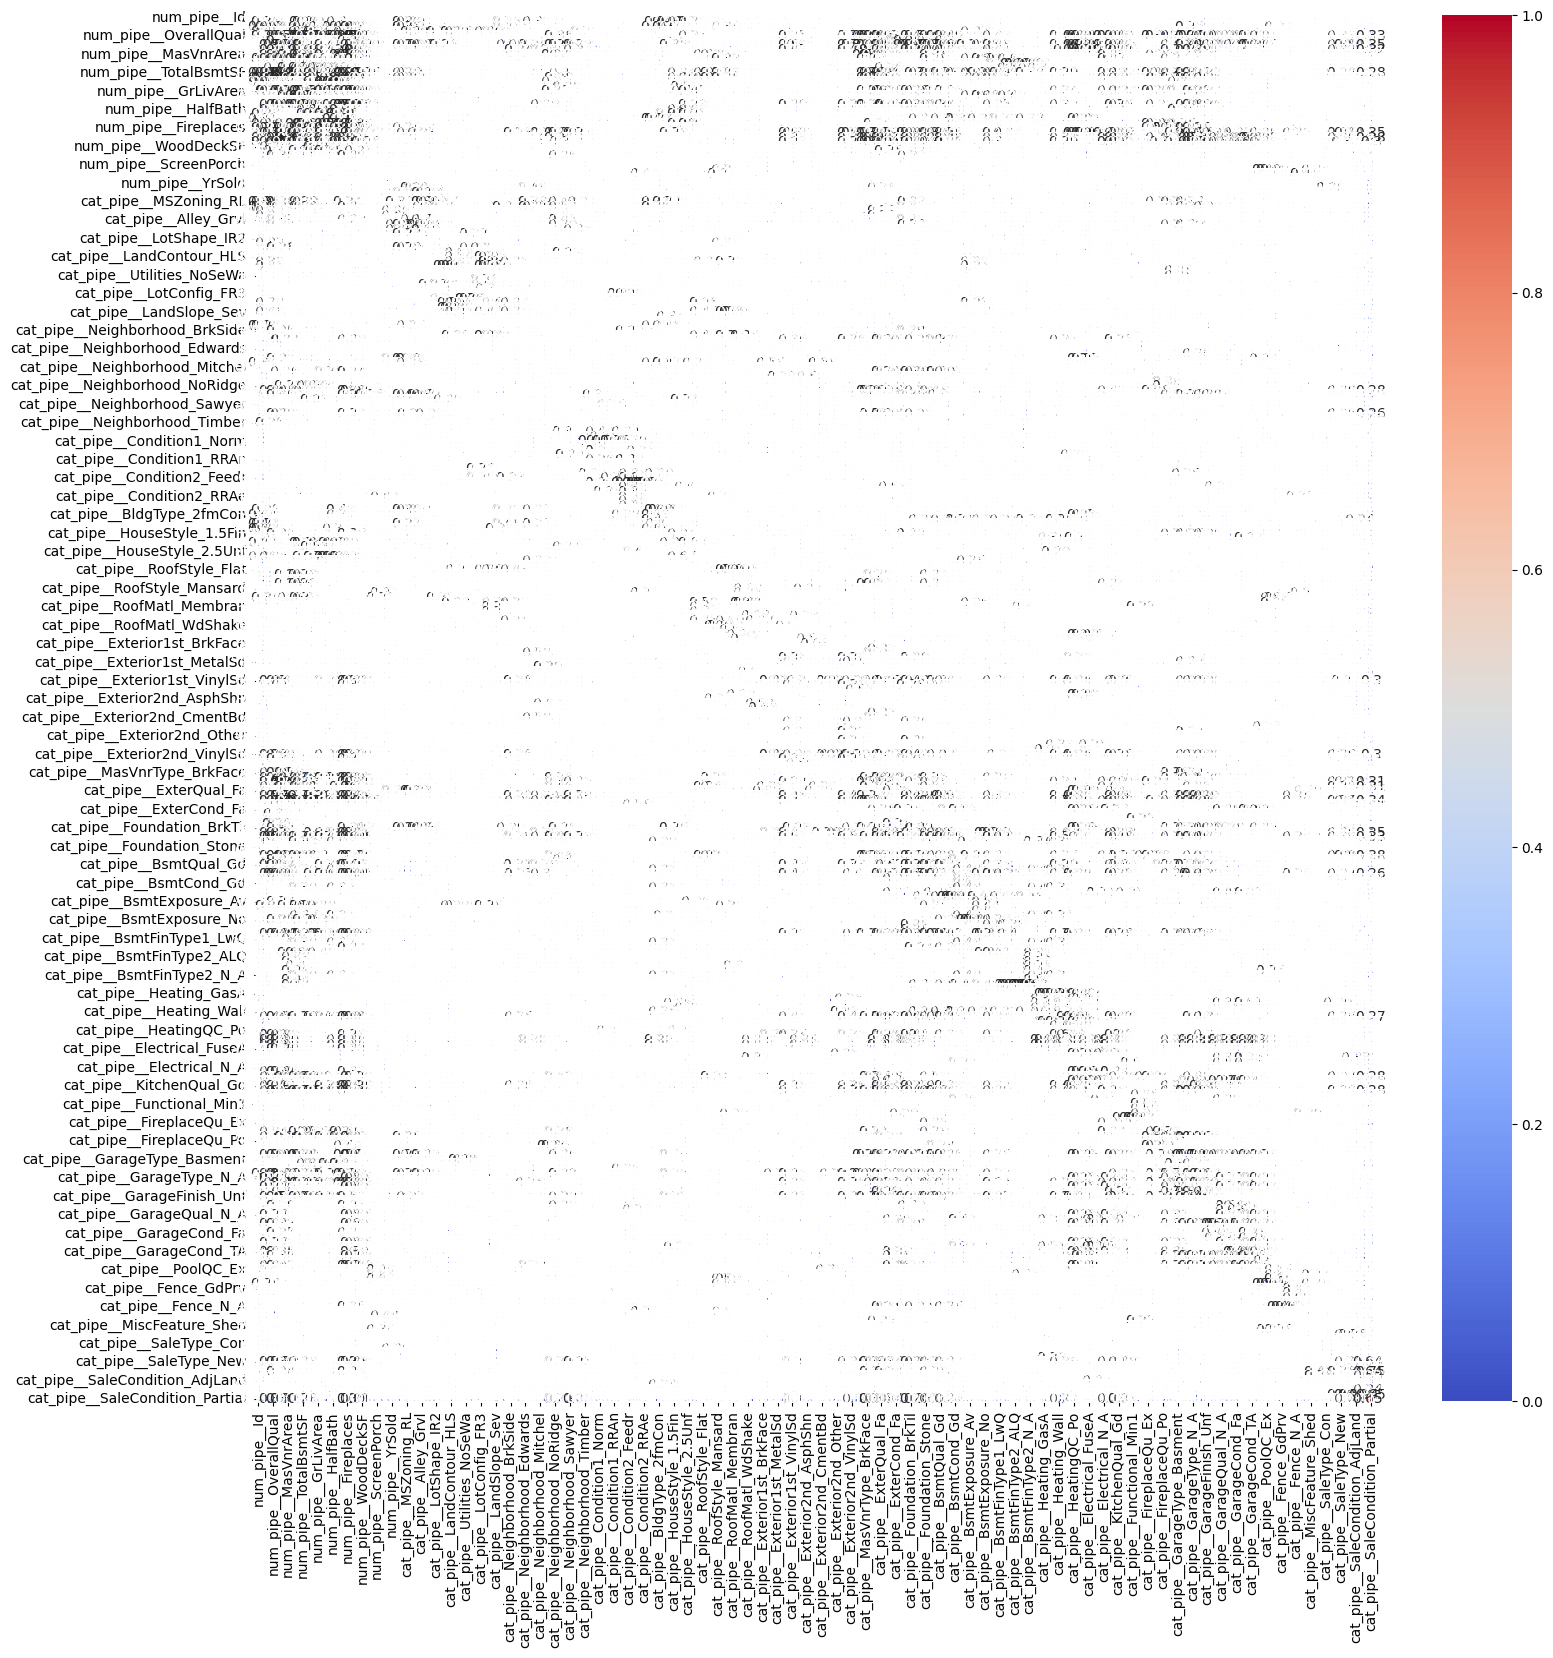

In [98]:
# Calcula a matriz de correlação absoluta entre as variáveis.
# O valor absoluto permite analisar apenas a intensidade da correlação, independentemente de ela ser positiva ou negativa.
corrMatrix = x_train_trans_fit.corr().abs()


# Define o tamanho do gráfico: 18 x 18 polegadas. Um tamanho maior facilita a visualização quando existem muitas variáveis.
plt.figure(figsize=(18, 18))


# Cria um mapa de calor (heatmap) para visualizar a matriz de correlação.
sns.heatmap(
    corrMatrix,       # Matriz de correlação que será visualizada
    annot=True,       # Exibe o valor da correlação dentro de cada célula
    cmap='coolwarm',  # Escala de cores para diferenciar níveis de correlação
    linewidths=0.4    # Adiciona linhas entre as células para facilitar a leitura
);

In [99]:
# Define o limite para considerar duas variáveis como altamente correlacionadas. Neste caso, correlações iguais ou superiores a 0.95 serão identificadas.
correlation_threshold = 0.95


# Cria uma lista vazia para armazenar os pares de variáveis que apresentam alta correlação.
highly_correlated_columns = []


# Obtém o número total de variáveis (colunas) da matriz de correlação.
num_features = len(corrMatrix.columns)


# Percorre a parte superior da matriz de correlação. O uso de i + 1 evita verificar a mesma combinação duas vezes, pois a matriz de correlação é simétrica.
for i in range(num_features):
    for j in range(i + 1, num_features):

        # Verifica se a correlação entre as duas variáveis
        # é igual ou superior ao limite definido (0.95).
        if corrMatrix.iloc[i, j] >= correlation_threshold:

            # Armazena:
            # 1. nome da primeira variável
            # 2. nome da segunda variável
            # 3. valor da correlação entre elas
            highly_correlated_columns.append(
                (
                    corrMatrix.columns[i],
                    corrMatrix.columns[j],
                    f"correlation = {round(corrMatrix.iloc[i, j], 2)}"
                )
            )


# Exibe os pares de variáveis que apresentam alta correlação. Essas variáveis podem indicar possível multicolinearidade.
print("Highly correlated columns:", highly_correlated_columns)

Highly correlated columns: [('num_pipe__PoolArea', 'cat_pipe__PoolQC_N_A', 'correlation = 0.99'), ('cat_pipe__Street_Grvl', 'cat_pipe__Street_Pave', 'correlation = 1.0'), ('cat_pipe__Utilities_AllPub', 'cat_pipe__Utilities_NoSeWa', 'correlation = 1.0'), ('cat_pipe__Exterior1st_CBlock', 'cat_pipe__Exterior2nd_CBlock', 'correlation = 1.0'), ('cat_pipe__Exterior1st_CemntBd', 'cat_pipe__Exterior2nd_CmentBd', 'correlation = 0.98'), ('cat_pipe__Exterior1st_MetalSd', 'cat_pipe__Exterior2nd_MetalSd', 'correlation = 0.97'), ('cat_pipe__Exterior1st_VinylSd', 'cat_pipe__Exterior2nd_VinylSd', 'correlation = 0.98'), ('cat_pipe__BsmtQual_N_A', 'cat_pipe__BsmtCond_N_A', 'correlation = 1.0'), ('cat_pipe__BsmtQual_N_A', 'cat_pipe__BsmtExposure_N_A', 'correlation = 0.98'), ('cat_pipe__BsmtQual_N_A', 'cat_pipe__BsmtFinType1_N_A', 'correlation = 1.0'), ('cat_pipe__BsmtQual_N_A', 'cat_pipe__BsmtFinType2_N_A', 'correlation = 1.0'), ('cat_pipe__BsmtCond_N_A', 'cat_pipe__BsmtExposure_N_A', 'correlation = 0.98

## Como interpretar os resultados?

### A. Variáveis que merecem atenção prioritária

Estas apresentam correlações de 1,00 ou muito próximas disso e podem representar redundância.

| Par de variáveis | Correlação | Minha recomendação |
|---|---:|---|
| `Street_Grvl` e `Street_Pave` | 1,00 | Manter apenas uma das dummies, se forem complementares e representarem as duas únicas categorias. |
| `Utilities_AllPub` e `Utilities_NoSeWa` | 1,00 | Verificar a distribuição das categorias. Se uma categoria for residual ou praticamente constante, avaliar a exclusão. |
| `CentralAir_N` e `CentralAir_Y` | 1,00 | Manter apenas uma das dummies, se representarem as duas únicas categorias. |
| `Exterior1st_CBlock` e `Exterior2nd_CBlock` | 1,00 | Investigar antes de excluir: são atributos distintos da residência. |
| `BsmtQual_N_A` e `BsmtFinType1_N_A` | 1,00 | Investigar a redundância semântica; podem indicar ausência de porão. |
| `GarageType_N_A` e `GarageFinish_N_A` | 1,00 | Investigar se ambas codificam a ausência de garagem. |
| `GarageQual_Ex` e `GarageCond_Ex` | 1,00 | Verificar se a coincidência ocorre em todas as observações e se os atributos têm significado distinto. |

**Importante:** correlação de 1,00 entre duas dummies não significa necessariamente que uma delas seja dispensável. Por exemplo, a qualidade e a condição da garagem são atributos diferentes, mesmo quando coincidem em determinada base.

### B. Variáveis que podem representar informações relacionadas

| Par ou grupo | Correlação | O que fazer |
|---|---:|---|
| `Exterior1st` e `Exterior2nd` | 0,97–0,98 | Avaliar separadamente; representam o revestimento exterior principal e o secundário. |
| `BsmtQual_N_A`, `BsmtCond_N_A`, `BsmtExposure_N_A`, `BsmtFinType1_N_A`, `BsmtFinType2_N_A` | 0,98–1,00 | Verificar se as categorias `N_A` representam ausência de porão. Evitar excluir todo o grupo indiscriminadamente. |
| `GarageType_N_A`, `GarageFinish_N_A`, `GarageQual_N_A`, `GarageCond_N_A` | 1,00 | Investigar a ausência de garagem; algumas dummies podem ser redundantes entre si. |
| `SaleType_New` e `SaleCondition_Partial` | 0,98 | Manter inicialmente e avaliar a contribuição de cada atributo para a previsão do preço. |
| `PoolArea` e `PoolQC_N_A` | 0,99 | Investigar a relação entre área da piscina e ausência de classificação de qualidade. |

As variáveis `Exterior1st` e `Exterior2nd`, por exemplo, descrevem revestimentos distintos. Mesmo que apresentem correlação elevada, uma delas ainda pode conter informação útil para prever o preço de venda.

# RETOMAR ANÁLISE DO LASSO
- Recuperação do pipeline LASSO com o melhor desempenho encontrado pelo GridSearchCV.
- Identificação das variáveis: recupera os nomes das variáveis após o pré-processamento dos dados.
- Extração dos coeficientes: obtém os coeficientes estimados pelo LASSO para cada variável.
- Organização dos resultados: cria uma tabela relacionando cada variável ao respectivo coeficiente.
- Identificação de variáveis eliminadas: marca as variáveis cujos coeficientes foram zerados pelo LASSO, indicando que não contribuem diretamente para a previsão do modelo ajustado.
- Ordenação dos coeficientes: organiza as variáveis em ordem crescente de valor absoluto dos coeficientes, facilitando a identificação daqueles mais próximos de zero.
- Apresentação dos resultados: exibe o melhor valor de alpha, a lista de variáveis com coeficientes zerados, a quantidade dessas variáveis e o total de variáveis consideradas.
Objetivo: avaliar como a regularização LASSO selecionou variáveis, reduzindo a complexidade do modelo ao zerar coeficientes considerados dispensáveis durante o ajuste.

Obs: um coeficiente zerado significa que a variável foi excluída da contribuição direta para a previsão pelo modelo LASSO ajustado. Isso não significa necessariamente que ela não tenha relação estatística com a variável-alvo.

In [102]:
# Recupera o melhor pipeline encontrado pelo GridSearchCV do LASSO
best_pipeline_lasso = search_lasso.best_estimator_

# Recupera os nomes das variáveis após o pré-processamento
feature_names = (
    best_pipeline_lasso
    .named_steps["columntransformer"]
    .get_feature_names_out()
)

# Recupera os coeficientes do Lasso
coefficients = (
    best_pipeline_lasso
    .named_steps["lasso"]
    .coef_
)

# Cria uma tabela associando variáveis e coeficientes
lasso_results = pd.DataFrame({
    "Variavel": feature_names,
    "Coeficiente": coefficients
})

# Identifica as variáveis cujo coeficiente foi zerado
lasso_results["Coeficiente_zero"] = (
    lasso_results["Coeficiente"] == 0
)

# Organiza a tabela
lasso_results = lasso_results.sort_values(
    by="Coeficiente",
    key=lambda x: x.abs(),
    ascending=True
)

print("Melhor alpha:", search_lasso.best_params_["lasso__alpha"])

print("\nVariáveis com coeficiente zero:")
print(
    lasso_results.loc[
        lasso_results["Coeficiente_zero"], "Variavel"
    ].to_list()
)

print("\nQuantidade de variáveis com coeficiente zero:",
      lasso_results["Coeficiente_zero"].sum())

print("\nQuantidade total de variáveis:",
      len(lasso_results))

Melhor alpha: 10

Variáveis com coeficiente zero:
['cat_pipe__Exterior2nd_BrkFace', 'cat_pipe__Exterior1st_Stucco', 'cat_pipe__Exterior2nd_AsphShn', 'cat_pipe__Exterior2nd_Brk Cmn', 'cat_pipe__Exterior2nd_CBlock', 'cat_pipe__Exterior2nd_Stone', 'cat_pipe__ExterCond_Po', 'cat_pipe__Exterior1st_Stone', 'cat_pipe__ExterCond_TA', 'cat_pipe__BsmtCond_Gd', 'cat_pipe__Alley_Grvl', 'cat_pipe__BsmtCond_N_A', 'cat_pipe__BsmtExposure_Av', 'cat_pipe__BsmtExposure_N_A', 'cat_pipe__MSZoning_RH', 'cat_pipe__BsmtQual_Fa', 'cat_pipe__Exterior1st_CBlock', 'cat_pipe__Exterior1st_BrkComm', 'cat_pipe__RoofMatl_WdShake', 'cat_pipe__Neighborhood_IDOTRR', 'cat_pipe__Condition1_Feedr', 'cat_pipe__Condition1_PosA', 'cat_pipe__Condition1_RRNn', 'cat_pipe__Condition2_Feedr', 'cat_pipe__Condition2_RRAn', 'cat_pipe__Condition2_RRNn', 'cat_pipe__BldgType_Duplex', 'cat_pipe__Neighborhood_Blueste', 'cat_pipe__RoofStyle_Flat', 'cat_pipe__RoofStyle_Gambrel', 'cat_pipe__RoofMatl_CompShg', 'cat_pipe__LandSlope_Gtl', 'cat_

## - Ordenação das variáveis: reorganiza a tabela lasso_results para apresentar primeiro as variáveis cujo coeficiente foi zerado pelo LASSO (True) e, em seguida, aquelas com coeficientes diferentes de zero (False).

**Objetivo**: facilitar a identificação das variáveis eliminadas pelo modelo durante o processo de regularização.

**Obs**: como não foi utilizado inplace=True nem houve atribuição do resultado a uma variável, a ordenação não é armazenada permanentemente em lasso_results.

In [103]:
# Ordenação das variáveis
lasso_results.sort_values(
    by="Coeficiente_zero",
    ascending=False
)

,Variavel,Coeficiente,Coeficiente_zero
150,cat_pipe__Exterior2nd_BrkFace,-0.000000,True
281,cat_pipe__MiscFeature_Gar2,-0.000000,True
208,cat_pipe__BsmtFinType2_N_A,0.000000,True
257,cat_pipe__GarageQual_Ex,0.000000,True
282,cat_pipe__MiscFeature_N_A,0.000000,True
...,...,...,...
28,num_pipe__WoodDeckSF,1882.881174,False
134,cat_pipe__Exterior1st_AsbShng,1919.670410,False
297,cat_pipe__SaleCondition_Alloca,1978.358479,False
236,cat_pipe__Functional_Min1,2022.066706,False


## - Identificação das candidatas à exclusão: seleciona os nomes das variáveis cujos coeficientes foram zerados pelo LASSO e armazena-os na lista variaveis_excluir_candidatas.
- Identificação das variáveis selecionadas: seleciona as variáveis com coeficientes diferentes de zero e armazena-as na lista variaveis_selecionadas. O operador ~ inverte a condição lógica, selecionando as variáveis que não tiveram seus coeficientes zerados.
- Contagem dos resultados: exibe a quantidade de variáveis candidatas à exclusão e a quantidade de variáveis mantidas pelo modelo.

**Objetivo**: separar as variáveis em dois grupos, de acordo com os coeficientes estimados pelo LASSO, para apoiar a análise de seleção de atributos.

**OBS**: as variáveis com coeficientes zerados são candidatas à exclusão, mas sua remoção definitiva deve considerar o desempenho preditivo do modelo após o retreinamento, além do conhecimento sobre o problema.

In [104]:
# Ordenação das variáveis
variaveis_excluir_candidatas = lasso_results.loc[
    lasso_results["Coeficiente_zero"],
    "Variavel"
].tolist()

variaveis_selecionadas = lasso_results.loc[
    ~lasso_results["Coeficiente_zero"],
    "Variavel"
].tolist()

print("Candidatas à exclusão:", len(variaveis_excluir_candidatas))
print("Variáveis selecionadas:", len(variaveis_selecionadas))

Candidatas à exclusão: 67
Variáveis selecionadas: 234


Total de variáveis: 301

Coeficientes zerados: 67 que correspondem à 22,3% do total de variáveis

Coeficientes não zerados: 234

Esses números descrevem a solução do Lasso com alpha = 10. Não comprovam, isoladamente, que a exclusão das 67 variáveis melhorará o modelo.

- Variáveis com coeficiente zero: não contribuíram com um efeito linear próprio na solução estimada pelo Lasso.
- Variáveis com coeficiente diferente de zero: foram mantidas pelo modelo, mas isso não significa que todas sejam importantes ou estatisticamente significativas.
- Variáveis altamente correlacionadas: o Lasso pode manter uma variável e zerar outra semelhante, sem que a segunda seja necessariamente irrelevante.

## Testando novos valores para Alpha
- Definição dos valores de alpha: estabelece oito valores candidatos para o parâmetro de regularização do LASSO. Quanto maior o alpha, maior tende a ser a penalização dos coeficientes, favorecendo que alguns sejam reduzidos a zero.
- Configuração do GridSearchCV: testa as combinações de parâmetros definidas em param_grid_lasso, utilizando o pipeline completo (full_pipeline_lasso).
- Validação cruzada (cv=5): divide os dados de treinamento em cinco partes, alternando os subconjuntos utilizados para ajuste e validação, a fim de avaliar o desempenho do modelo.
- Critério de avaliação (scoring): utiliza o RMSE (Root Mean Squared Error), que mede a magnitude dos erros de previsão, penalizando mais fortemente os erros maiores. O prefixo neg é uma convenção do scikit-learn, pois a ferramenta maximiza as pontuações; por isso, o sinal é invertido na apresentação do resultado.
- Execução da busca: search_lasso.fit(x_train, y_train) testa os valores de alpha e identifica aquele com o melhor desempenho médio na validação cruzada.
- Apresentação dos resultados: exibe o melhor valor de alpha encontrado e o RMSE médio de validação cruzada correspondente.

**Objetivo**: selecionar o nível de regularização do LASSO que apresenta o menor RMSE médio na validação cruzada, equilibrando a qualidade preditiva e a redução dos coeficientes.

**OBS**: o melhor alpha depende dos dados, do pré-processamento e dos valores testados. Portanto, o resultado representa o melhor desempenho entre os candidatos avaliados, não necessariamente o melhor valor possível.

In [106]:
# Testando novos valores para Alpha
param_grid_lasso = {
    "lasso__alpha": [1, 5, 10, 25, 50, 100, 250, 500]
}

search_lasso = GridSearchCV(
    full_pipeline_lasso,
    param_grid_lasso,
    cv=5,
    scoring="neg_root_mean_squared_error",
    verbose=1,
    error_score="raise"
)

search_lasso.fit(x_train, y_train)

print("Melhor alpha:", search_lasso.best_params_)
print("RMSE médio de validação cruzada:",
      -search_lasso.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhor alpha: {'lasso__alpha': 100}
RMSE médio de validação cruzada: 33505.3412477821


## Ampliação da faixa de regularização para Alpha
- Ampliação da faixa de regularização: define novos valores de alpha, entre 50 e 1000, para investigar o desempenho do LASSO sob uma penalização mais intensa dos coeficientes.
- Configuração da busca: utiliza o GridSearchCV com validação cruzada de cinco partes (cv=5) e o RMSE como critério de avaliação.
- Treinamento e comparação: executa o pipeline completo para cada valor de alpha e compara os respectivos RMSE médios de validação cruzada.
- Apresentação dos resultados: exibe o melhor alpha encontrado dentro da nova faixa e o RMSE médio correspondente.
  
**Objetivo**: investigar se valores mais elevados de regularização melhoram o desempenho preditivo do modelo e promovem maior redução dos coeficientes.

**OBS**: essa busca é especialmente útil quando os testes anteriores indicam que valores maiores de alpha podem ser vantajosos. Entretanto, um alpha maior não garante menor RMSE; a escolha deve ser baseada no desempenho observado na validação cruzada.

In [107]:
# Ampliação da faixa de regularização para Alpha

param_grid_lasso = {
    "lasso__alpha": [50, 100, 150, 200, 300, 500, 750, 1000]
}

search_lasso = GridSearchCV(
    full_pipeline_lasso,
    param_grid_lasso,
    cv=5,
    scoring="neg_root_mean_squared_error",
    verbose=1,
    error_score="raise"
)

search_lasso.fit(x_train, y_train)

print("Melhor alpha:", search_lasso.best_params_)
print("RMSE médio de validação cruzada:",
      -search_lasso.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhor alpha: {'lasso__alpha': 150}
RMSE médio de validação cruzada: 33346.5682466131


- **Recuperação do melhor modelo:** obtém o pipeline LASSO com o melhor desempenho identificado pelo `GridSearchCV`.
- **Recuperação dos atributos:** extrai os nomes das variáveis após o pré-processamento e os coeficientes estimados pelo LASSO.
- **Construção da tabela de resultados:** associa cada variável ao seu coeficiente e identifica aquelas cujos coeficientes foram zerados.
- **Separação das variáveis:** cria duas listas: `variaveis_excluir_candidatas`, com coeficientes iguais a zero, e `variaveis_selecionadas`, com coeficientes diferentes de zero.
- **Apresentação dos resultados:** exibe o `alpha` selecionado, a quantidade de variáveis zeradas, a quantidade de variáveis selecionadas e a lista de candidatas à exclusão.

**Objetivo:** identificar quais variáveis o LASSO manteve ou eliminou no modelo final, utilizando o valor de regularização selecionado pela validação cruzada.

**OBS:** as variáveis com coeficientes zerados são candidatas à exclusão, mas sua remoção definitiva deve ser avaliada mediante o retreinamento do modelo sem essas variáveis e a comparação do desempenho preditivo em dados de validação ou teste.

In [109]:
best_pipeline_lasso = search_lasso.best_estimator_

feature_names = (
    best_pipeline_lasso
    .named_steps["columntransformer"]
    .get_feature_names_out()
)

coefficients = (
    best_pipeline_lasso
    .named_steps["lasso"]
    .coef_
)

lasso_results = pd.DataFrame({
    "Variavel": feature_names,
    "Coeficiente": coefficients
})

lasso_results["Coeficiente_zero"] = (
    lasso_results["Coeficiente"] == 0
)

variaveis_excluir_candidatas = lasso_results.loc[
    lasso_results["Coeficiente_zero"], "Variavel"
].tolist()

variaveis_selecionadas = lasso_results.loc[
    ~lasso_results["Coeficiente_zero"], "Variavel"
].tolist()

print("Alpha selecionado:",
      search_lasso.best_params_["lasso__alpha"])

print("Variáveis com coeficiente zero:",
      len(variaveis_excluir_candidatas))

print("Variáveis selecionadas:",
      len(variaveis_selecionadas))

print("\nCandidatas à exclusão:")
print(variaveis_excluir_candidatas)

Alpha selecionado: 150
Variáveis com coeficiente zero: 203
Variáveis selecionadas: 98

Candidatas à exclusão:
['num_pipe__BsmtUnfSF', 'num_pipe__1stFlrSF', 'num_pipe__2ndFlrSF', 'num_pipe__GarageArea', 'num_pipe__OpenPorchSF', 'num_pipe__EnclosedPorch', 'num_pipe__MiscVal', 'cat_pipe__MSZoning_FV', 'cat_pipe__MSZoning_RH', 'cat_pipe__Street_Grvl', 'cat_pipe__Street_Pave', 'cat_pipe__Alley_Grvl', 'cat_pipe__Alley_N_A', 'cat_pipe__Alley_Pave', 'cat_pipe__LotShape_IR1', 'cat_pipe__LotShape_IR3', 'cat_pipe__LotShape_Reg', 'cat_pipe__LandContour_Low', 'cat_pipe__LandContour_Lvl', 'cat_pipe__Utilities_AllPub', 'cat_pipe__Utilities_NoSeWa', 'cat_pipe__LotConfig_Corner', 'cat_pipe__LotConfig_FR3', 'cat_pipe__LotConfig_Inside', 'cat_pipe__LandSlope_Gtl', 'cat_pipe__LandSlope_Sev', 'cat_pipe__Neighborhood_Blmngtn', 'cat_pipe__Neighborhood_Blueste', 'cat_pipe__Neighborhood_BrDale', 'cat_pipe__Neighborhood_ClearCr', 'cat_pipe__Neighborhood_CollgCr', 'cat_pipe__Neighborhood_IDOTRR', 'cat_pipe__Neig

## Análise dos resultados do modelo LASSO

- **Parâmetro de regularização selecionado:** o `GridSearchCV` identificou `alpha = 150` como o melhor valor entre os candidatos testados, segundo o RMSE médio da validação cruzada. Esse valor define a intensidade da penalização aplicada aos coeficientes do modelo.

- **Redução do número de variáveis:** das 301 variáveis geradas após o pré-processamento, 203 tiveram seus coeficientes zerados, enquanto 98 permaneceram com coeficientes diferentes de zero. Portanto, o LASSO zerou aproximadamente **67,44% das variáveis**, mantendo cerca de **32,56%** com contribuição direta para as previsões do modelo ajustado.

- **Seleção de atributos:** os resultados demonstram que o LASSO promoveu uma redução expressiva da dimensionalidade, favorecendo um modelo mais parcimonioso. As 203 variáveis com coeficientes zerados são candidatas à exclusão, enquanto as 98 restantes constituem o conjunto de variáveis selecionadas pelo modelo.

- **Interpretação das variáveis categóricas:** grande parte das variáveis candidatas à exclusão corresponde a categorias geradas pelo processo de codificação das variáveis qualitativas. Por exemplo, categorias de `Neighborhood`, `Exterior1st`, `Foundation` e `GarageType` tiveram seus coeficientes zerados. Isso indica que essas categorias não apresentaram contribuição linear adicional suficiente para manter coeficientes diferentes de zero, considerando as demais variáveis e a penalização aplicada.

- **Interpretação das variáveis numéricas:** variáveis como `BsmtUnfSF`, `1stFlrSF`, `2ndFlrSF` e `GarageArea` também tiveram seus coeficientes zerados. Esse resultado não significa necessariamente que essas características não estejam relacionadas ao preço dos imóveis. Sua contribuição pode estar parcialmente representada por outras variáveis correlacionadas, ou ter sido reduzida pela regularização.

- **Implicações para a modelagem:** a redução do número de coeficientes pode facilitar a interpretação do modelo e diminuir sua complexidade. Entretanto, a quantidade de variáveis eliminadas, isoladamente, não comprova melhora na capacidade preditiva nem garante maior generalização para dados novos.

### Conclusão e próximos passos

- O LASSO selecionou 98 das 301 variáveis geradas pelo pré-processamento, zerando os coeficientes das outras 203.
- O valor `alpha = 150` representa o melhor parâmetro de regularização encontrado na busca realizada, considerando os valores testados e o critério de validação cruzada adotado.
- Antes de excluir definitivamente as variáveis com coeficientes zerados, recomenda-se avaliar o desempenho do modelo em um conjunto de teste independente e comparar o RMSE com o modelo de referência.
- Como as variáveis categóricas foram transformadas em indicadores, a exclusão de uma categoria não equivale necessariamente à exclusão de toda a variável original. A seleção ocorreu no nível das variáveis transformadas.
- Recomenda-se também verificar se o pré-processamento utiliza codificação *one-hot* com categorias de referência ou sem categoria de referência, pois isso influencia a interpretação dos coeficientes e das categorias zeradas.

**Síntese:** o resultado evidencia que o LASSO realizou uma seleção expressiva de atributos, reduzindo o número de coeficientes não nulos de 301 para 98. A relevância dessa redução deverá ser confirmada pela comparação do desempenho preditivo e pela avaliação da estabilidade das variáveis selecionadas.

## Classificação das variáveis para avaliação de exclusão

Essas foram as variáveis sugeridas para serem excluídas, é necessário avaliar melhor que variáveis são essas antes de prosseguir com a exclusão de fato.

| Categoria | Variáveis identificadas | Critério de avaliação |
|---|---|---|
| **Variáveis numéricas** | `BsmtUnfSF`, `1stFlrSF`, `2ndFlrSF`, `GarageArea`, `OpenPorchSF`, `EnclosedPorch`, `MiscVal` | Avaliar a exclusão individual das variáveis com coeficiente zerado pelo LASSO, verificando sua contribuição preditiva e a possível redundância com outros atributos. |
| **Variáveis categóricas** | `MSZoning`, `Street`, `Alley`, `LotShape`, `LandContour`, `Utilities`, `LotConfig`, `LandSlope`, `Neighborhood`, `Condition1`, `Condition2`, `BldgType`, `HouseStyle`, `RoofStyle`, `RoofMatl`, `Exterior1st`, `Exterior2nd`, `MasVnrType`, `ExterQual`, `ExterCond`, `Foundation`, `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`, `Heating`, `HeatingQC`, `CentralAir`, `Electrical`, `KitchenQual`, `Functional`, `FireplaceQu`, `GarageType`, `GarageQual`, `GarageCond`, `PavedDrive`, `PoolQC`, `Fence`, `MiscFeature`, `SaleType`, `SaleCondition` | Analisar individualmente as categorias cujos coeficientes foram zerados e aquelas que permaneceram diferentes de zero. Não excluir a variável original automaticamente, pois suas categorias podem apresentar contribuições distintas para a previsão. |
| **Variáveis potencialmente correlacionadas** | `1stFlrSF`, `2ndFlrSF`, `GrLivArea`; `BsmtUnfSF`, `BsmtFinSF1`, `BsmtFinSF2`, `TotalBsmtSF`; `GarageArea`, `GarageCars`; `YearBuilt`, `YearRemodAdd`, `GarageYrBlt`; `TotRmsAbvGrd`, `GrLivArea`, `BedroomAbvGr`; `Exterior1st`, `Exterior2nd` | Verificar correlações, redundância informacional e contribuição incremental. Quando duas variáveis representam informações semelhantes, comparar o desempenho do modelo antes de decidir qual manter ou excluir. |

In [112]:
# 1. Recupera os atributos com coeficiente zero no LASSO
to_drop = (
    lasso_results.loc[
        lasso_results["Coeficiente_zero"],
        "Variavel"
    ]
    .head(21)
    .tolist()
)

print("Quantidade de atributos a excluir:", len(to_drop))
print("Atributos candidatos à exclusão:")
print(to_drop)

# 2. Exclui os atributos dos conjuntos transformados, mas antes se confere se os nomes existem nos DataFrames
ausentes_train = [
    col for col in to_drop
    if col not in x_train_trans_fit.columns
]

ausentes_test = [
    col for col in to_drop
    if col not in x_test_trans_fit.columns
]

if ausentes_train or ausentes_test:
    print("\nAtenção: alguns nomes não correspondem às colunas.")
    print("Ausentes no treino:", ausentes_train)
    print("Ausentes no teste:", ausentes_test)
else:
    x_train_corr = x_train_trans_fit.drop(
        columns=to_drop
    ).copy()

    x_test_corr = x_test_trans_fit.drop(
        columns=to_drop
    ).copy()

    print("\nDimensão original do treino:",
          x_train_trans_fit.shape)
    print("Dimensão do treino após exclusão:",
          x_train_corr.shape)

    print("Dimensão original do teste:",
          x_test_trans_fit.shape)
    print("Dimensão do teste após exclusão:",
          x_test_corr.shape)


Quantidade de atributos a excluir: 21
Atributos candidatos à exclusão:
['num_pipe__BsmtUnfSF', 'num_pipe__1stFlrSF', 'num_pipe__2ndFlrSF', 'num_pipe__GarageArea', 'num_pipe__OpenPorchSF', 'num_pipe__EnclosedPorch', 'num_pipe__MiscVal', 'cat_pipe__MSZoning_FV', 'cat_pipe__MSZoning_RH', 'cat_pipe__Street_Grvl', 'cat_pipe__Street_Pave', 'cat_pipe__Alley_Grvl', 'cat_pipe__Alley_N_A', 'cat_pipe__Alley_Pave', 'cat_pipe__LotShape_IR1', 'cat_pipe__LotShape_IR3', 'cat_pipe__LotShape_Reg', 'cat_pipe__LandContour_Low', 'cat_pipe__LandContour_Lvl', 'cat_pipe__Utilities_AllPub', 'cat_pipe__Utilities_NoSeWa']

Dimensão original do treino: (1168, 301)
Dimensão do treino após exclusão: (1168, 280)
Dimensão original do teste: (292, 301)
Dimensão do teste após exclusão: (292, 280)


- Base de dados: 1.460 observações, divididas em 1.168 para treino e 292 para teste.
- LASSO: selecionou alpha = 150, com RMSE médio de validação cruzada de aproximadamente 33.346,57.
- Redução de atributos: foram excluídos 21 dos 301 atributos, correspondendo a 6,98%. O conjunto passou a ter 280 atributos.
- Critério utilizado: os 21 primeiros atributos com coeficientes zerados pelo LASSO, conforme a ordem de lasso_results.
Ponto de atenção: a exclusão foi executada corretamente, mas isso não significa que os 21 atributos sejam necessariamente os menos importantes para a previsão. Além disso, você excluiu todas as categorias codificadas de algumas variáveis, como Street e Utilities, eliminando completamente essas informações do modelo reduzido.

Próximo passo: retreinar o modelo com os 280 atributos e comparar o RMSE com o modelo original, usando o mesmo protocolo de avaliação. Se o desempenho se mantiver semelhante ou melhorar, a redução poderá ser considerada útil.

### - **Procedimento metodológico**: Foram implementados e treinados sete algoritmos de regressão: Árvore de Decisão, K-Nearest Neighbors (KNN), Regressão Linear, Random Forest, Support Vector Regression (SVR), Lasso e Ridge, utilizando o conjunto de variáveis definido para a análise de colinearidade. Após o treinamento, cada modelo foi utilizado para gerar previsões sobre o conjunto de teste, e seu desempenho foi avaliado por meio do coeficiente de determinação (\\(R^2\\)). Os resultados foram armazenados em uma estrutura comparativa, permitindo analisar o desempenho dos diferentes algoritmos sob a condição investigada.

### - **Objetivo e fundamentação**: O procedimento teve como finalidade examinar em que medida a presença de variáveis explicativas altamente correlacionadas pode afetar o desempenho preditivo de diferentes métodos de regressão. A multicolinearidade pode comprometer a estabilidade dos coeficientes e dificultar a interpretação dos efeitos individuais das variáveis, sobretudo nos modelos lineares tradicionais. Métodos regularizados, como Lasso e Ridge, incorporam penalizações que podem reduzir determinados efeitos associados à colinearidade, enquanto algoritmos baseados em árvores e métodos não lineares apresentam mecanismos distintos de aprendizagem e tratamento das relações entre as variáveis. A comparação do \\(R^2\\) permite verificar diferenças na proporção da variabilidade da variável-alvo explicada pelas previsões de cada modelo no conjunto de teste.

### - **Interpretação dos resultados**: A análise comparativa permite identificar quais algoritmos apresentam melhor desempenho preditivo no cenário avaliado e investigar sua sensibilidade às características do conjunto de dados. Entretanto, diferenças no \\(R^2\\), isoladamente, não demonstram que a colinearidade seja a causa das variações observadas. Para avaliar especificamente seu impacto, é necessário comparar os resultados obtidos nesse cenário com aqueles de uma configuração de referência, mantendo os mesmos conjuntos de treinamento e teste e condições metodológicas equivalentes. Além disso, como o código utiliza variáveis distintas no modelo Ridge em relação aos demais algoritmos, essa diferença deve ser corrigida para assegurar a comparabilidade dos resultados.

In [114]:
# Decision tree.
corr_tree = DecisionTreeRegressor()
corr_tree.fit(x_train_corr, y_train)
corr_tree_pred = corr_tree.predict(x_test_corr)

# K-Nearest Neighbors.
corr_knn = KNeighborsRegressor(n_neighbors=1)
corr_knn.fit(x_train_corr, y_train)
corr_knn_pred = corr_knn.predict(x_test_corr)

# Linear Regresion
corr_linear_reg = LinearRegression()
corr_linear_reg.fit(x_train_corr, y_train)
corr_linear_reg_pred = corr_linear_reg.predict(x_test_corr)

# Random Forest Regression
corr_random_forest_reg = RandomForestRegressor()
corr_random_forest_reg.fit(x_train_corr, y_train)
corr_random_forest_reg_pred = corr_random_forest_reg.predict(x_test_corr)

# SVR 
corr_svr_reg = SVR()
corr_svr_reg.fit(x_train_corr, y_train)
corr_svr_reg_pred = corr_svr_reg.predict(x_test_corr)

# Lasso
corr_lasso_reg = Lasso()
corr_lasso_reg.fit(x_train_corr, y_train)
corr_lasso_reg_pred = corr_lasso_reg.predict(x_test_corr)

# Ridge - For Rridge it is need to change the algorithm a little
x_train_prepro = preprocessor.fit_transform(x_train)
x_test_prepro = preprocessor.transform(x_test)
corr_ridge_reg = Ridge()
corr_ridge_reg.fit(x_train_prepro, y_train)
corr_ridge_reg_pred = corr_ridge_reg.predict(x_test_prepro)

performances.loc["collinearity", "decision_tree"] = r2_score(y_test, corr_tree_pred)
performances.loc["collinearity", "knn"] = r2_score(y_test, corr_knn_pred)
performances.loc["collinearity", "linear_regression"] = r2_score(y_test, corr_linear_reg_pred)
performances.loc["collinearity", "random_forest"] = r2_score(y_test, corr_random_forest_reg_pred)
performances.loc["collinearity", "svr"] = r2_score(y_test, corr_svr_reg_pred)
performances.loc["collinearity", "lasso"] = r2_score(y_test, corr_lasso_reg_pred)
performances.loc["collinearity", "ridge"] = r2_score(y_test, corr_ridge_reg_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415


### K-Best (*SelectKBest*)

- **Definição:** O *SelectKBest* é um método de seleção de variáveis (*feature selection*) que seleciona as `K` variáveis preditoras mais relevantes para explicar ou prever a variável-alvo (*target*), com base em uma função estatística de avaliação previamente definida.

- **Objetivo:** Reduzir a dimensionalidade do conjunto de dados, preservando as variáveis que apresentam maior evidência de associação estatística com a variável-alvo. Essa redução pode diminuir a complexidade do modelo, reduzir custos computacionais e, dependendo dos dados e do algoritmo utilizado, contribuir para melhorar a capacidade de generalização e reduzir o risco de sobreajuste (*overfitting*).

- **Critério de seleção:** A relevância das variáveis é determinada por uma função de pontuação (*score function*), como o teste F para regressão (`f_regression`) ou a informação mútua (`mutual_info_regression`). A escolha do critério influencia quais variáveis serão selecionadas e quais tipos de relação estatística poderão ser identificados.

- **Limitações:** O método avalia a relevância das variáveis individualmente em relação à variável-alvo, conforme o critério escolhido. Portanto, não garante a seleção do melhor conjunto de variáveis para todos os modelos, nem identifica necessariamente interações entre preditores. Além disso, a seleção deve ser ajustada exclusivamente com os dados de treinamento para evitar vazamento de informação (*data leakage*).

#### OBS.: Diferenças entre os métodos de seleção de variáveis

- **Variance Threshold:** remove variáveis cuja variância está abaixo de um limite predefinido, identificando atributos com pouca ou nenhuma variação nos dados. O método não considera a relação entre as variáveis preditoras e a variável-alvo.

- **K-Best (*SelectKBest*):** seleciona as `K` variáveis com as maiores pontuações em um critério estatístico previamente definido, avaliando sua associação individual com a variável-alvo. A seleção depende da função de pontuação utilizada, como o teste F ou a informação mútua.

### Aplicação do SelectKBest com F-regression

- **Construção da pipeline:** Foi criada uma pipeline que integra o pré-processamento dos dados, a normalização das variáveis por meio do `MinMaxScaler` e a seleção de variáveis com o `SelectKBest`, utilizando `f_regression` como função de pontuação e definindo `k=10`. Dessa forma, são selecionadas as dez variáveis preditoras com as maiores pontuações no teste F, considerando sua associação estatística individual com a variável-alvo.

- **Ajuste e transformação do conjunto de treinamento:** A pipeline foi ajustada aos dados de treinamento por meio de `fit_transform()`. Nessa etapa, os parâmetros do pré-processamento são estimados e as dez variáveis mais relevantes são selecionadas com base exclusivamente nos dados de treinamento e nos valores de `y_train`.

- **Transformação do conjunto de teste:** O método `transform()` aplica ao conjunto de teste as transformações e a seleção de variáveis definidas durante o treinamento, sem recalcular os critérios de seleção. Esse procedimento preserva a consistência entre os conjuntos e evita o vazamento de informação (*data leakage*).

- **Objetivo:** Reduzir a dimensionalidade do conjunto de dados e avaliar se a utilização das dez variáveis selecionadas contribui para o desempenho preditivo dos modelos, potencialmente reduzindo a complexidade computacional e favorecendo a generalização.

In [117]:
# Creando a pipeline e iniciando KBest, udando f-regression e k=10.
pipeline_kbest = make_pipeline(preprocessor,
                               MinMaxScaler(),
                               SelectKBest(score_func=f_regression, k=10)).set_output(transform='pandas') 

# Utilize o pipeline criado acima para ajustar e transformar os dados de treino
x_train_kbest = pipeline_kbest.fit_transform(x_train, y_train)

# Transforme o conjunto de teste
x_test_kbest = pipeline_kbest.transform(x_test)

## Treinamento e avaliação dos modelos após a seleção de variáveis com K-Best

- **Treinamento dos modelos:** Foram treinados sete algoritmos de regressão — Árvore de Decisão, *K-Nearest Neighbors* (KNN), Regressão Linear, *Random Forest*, *Support Vector Regression* (SVR), Lasso e Ridge — utilizando o conjunto de dados resultante da seleção das dez variáveis preditoras com maiores pontuações no teste F, realizada pelo método `SelectKBest`.

- **Geração das previsões:** Após o ajuste de cada algoritmo aos dados de treinamento, foram geradas previsões para o conjunto de teste. No KNN, foi definido `n_neighbors=12`, estabelecendo a utilização dos 12 vizinhos mais próximos para estimar os valores da variável-alvo.

- **Avaliação do desempenho:** O coeficiente de determinação (\(R^2\)) foi calculado para cada modelo, e os resultados foram registrados na tabela `performances`, na linha identificada como `KBest_10`. Essa estrutura permite comparar o desempenho preditivo dos diferentes algoritmos após a redução do número de variáveis explicativas.

- **Objetivo:** Investigar se a seleção das dez variáveis mais relevantes segundo o critério estatístico adotado permite preservar ou melhorar a capacidade preditiva dos modelos, reduzindo simultaneamente a dimensionalidade dos dados. Os resultados podem ser comparados aos obtidos com o conjunto original de variáveis para avaliar os efeitos da seleção sobre o desempenho dos algoritmos.

- **Interpretação:** Valores de \(R^2\) mais elevados indicam melhor ajuste preditivo no conjunto de teste, enquanto valores inferiores podem sinalizar perda de informação relevante decorrente da exclusão de variáveis. A seleção de um número menor de preditores, entretanto, não garante, por si só, melhor desempenho ou menor sobreajuste.

In [118]:
# Armazenar a árvore de decisão

# Store the decision tree
tree = DecisionTreeRegressor()
#Fit the decicion tree 
tree.fit(x_train_kbest, y_train)
#Predict the test data 
tree_pred_kbest = tree.predict(X = x_test_kbest)

#Store the K-Nearest Neighbor
neigh = KNeighborsRegressor(n_neighbors=12)
#Fit 
neigh.fit(x_train_kbest, y_train)
#Predict the test data 
knn_pred_kbest = neigh.predict(X = x_test_kbest)

#  Linear Regression
linear_reg = LinearRegression()
linear_reg.fit(x_train_kbest, y_train)
linear_reg_pred = linear_reg.predict(x_test_kbest)

# Random Forest Regression
random_forest_reg = RandomForestRegressor()
random_forest_reg.fit(x_train_kbest, y_train)
random_forest_reg_pred = random_forest_reg.predict(x_test_kbest)

# SVR 
svr_reg = SVR()
svr_reg.fit(x_train_kbest, y_train)
svr_reg_pred = svr_reg.predict(x_test_kbest)

# Lasso
lasso_reg = Lasso()
lasso_reg.fit(x_train_kbest, y_train)
lasso_reg_pred = lasso_reg.predict(x_test_kbest)

# Ridge
ridge_reg = Ridge()
ridge_reg.fit(x_train_kbest, y_train)
ridge_reg_pred = ridge_reg.predict(x_test_kbest)

# Para armazenar o R² de cada modelo após a seleção das 10 melhores variáveis pelo K-Best, 
# e exibir uma tabela performances permite comparar o desempenho dos modelos usando K-Best.
    
performances.loc["KBest_10", "decision_tree"]= r2_score(y_test, tree_pred_kbest)
performances.loc["KBest_10", "knn"] = r2_score(y_test, knn_pred_kbest)
performances.loc["KBest_10", "linear_regression"] = r2_score(y_test, linear_reg_pred)
performances.loc["KBest_10", "random_forest"] = r2_score(y_test, random_forest_reg_pred)
performances.loc["KBest_10", "svr"] = r2_score(y_test, svr_reg_pred)
performances.loc["KBest_10", "lasso"] = r2_score(y_test, lasso_reg_pred)
performances.loc["KBest_10", "ridge"] = r2_score(y_test, ridge_reg_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362


## Eliminação Recursiva de Atributos (RFE)

- **Definição:** A *Recursive Feature Elimination* (RFE) é uma técnica de seleção de variáveis que elimina iterativamente os preditores menos relevantes, utilizando um modelo de aprendizagem supervisionada para estimar sua importância relativa. O procedimento é repetido até que seja atingido o número de variáveis previamente definido.

- **Funcionamento:** Inicialmente, o algoritmo é ajustado ao conjunto de treinamento completo. Em seguida, as variáveis são classificadas segundo os critérios de importância fornecidos pelo modelo, e aquelas consideradas menos relevantes são removidas progressivamente. O processo continua até que seja obtido o subconjunto de variáveis desejado.

- **Modelos compatíveis:** O RFE pode ser aplicado a diferentes algoritmos de regressão, desde que o estimador utilizado forneça um critério de importância das variáveis, como os coeficientes dos modelos lineares ou os atributos `feature_importances_` de modelos baseados em árvores. Entre os exemplos estão Regressão Linear, Ridge, Lasso, ElasticNet, Árvores de Decisão, Random Forest e SVR com kernel linear.

- **Limitações e aplicabilidade:** A utilização do RFE depende da existência de um estimador capaz de fornecer medidas de importância das variáveis. O K-Nearest Neighbors (KNN), por exemplo, não produz diretamente coeficientes ou medidas intrínsecas de importância dos preditores, pois suas estimativas se baseiam na proximidade entre observações no espaço de atributos. Embora seja possível utilizar o RFE com o KNN mediante um estimador auxiliar que forneça a importância das variáveis, essa abordagem exige uma etapa adicional de modelagem.

- **Decisão metodológica:** Optou-se por não aplicar o RFE diretamente ao KNN, uma vez que o algoritmo não disponibiliza, por padrão, os atributos de importância exigidos pelo procedimento. Essa decisão evita a introdução de um estimador auxiliar exclusivamente para viabilizar a seleção recursiva. Ressalta-se, contudo, que essa escolha não implica incompatibilidade absoluta entre RFE e KNN, mas apenas a ausência de um mecanismo nativo de avaliação da importância das variáveis no KNN.

## RFE / RFECV (*Recursive Feature Elimination with Cross-Validation*)

- **Definição:** A *Recursive Feature Elimination* (RFE), ou Eliminação Recursiva de Atributos, é um método de seleção de variáveis que identifica e elimina progressivamente os preditores menos relevantes para a modelagem. O procedimento começa com o conjunto de variáveis disponível, ajusta um modelo preditivo, classifica os atributos segundo sua importância relativa e remove aqueles com menor contribuição, repetindo o processo até atingir o número de variáveis previamente estabelecido.

- **Extensão com validação cruzada:** O *Recursive Feature Elimination with Cross-Validation* (RFECV) amplia o RFE ao incorporar a validação cruzada (*cross-validation*) para determinar automaticamente o número de variáveis a manter. Em vez de exigir que essa quantidade seja definida antecipadamente, o RFECV avalia o desempenho de diferentes subconjuntos de variáveis em múltiplas partições dos dados de treinamento e seleciona a quantidade associada ao melhor desempenho médio, segundo uma métrica previamente definida.

- **Critério de importância:** A eliminação recursiva depende de um estimador capaz de atribuir importância às variáveis. Em modelos lineares, essa avaliação pode utilizar os coeficientes estimados; em modelos baseados em árvores, como `DecisionTreeRegressor` e `RandomForestRegressor`, pode utilizar o atributo `feature_importances_`. A seleção resultante depende tanto do estimador quanto do critério utilizado para avaliar o desempenho.

- **Diferença entre RFE e RFECV:** O RFE elimina variáveis até alcançar uma quantidade definida previamente pelo pesquisador. O RFECV, por sua vez, utiliza validação cruzada para identificar a quantidade de variáveis que proporciona o melhor desempenho médio entre os subconjuntos avaliados.

- **Objetivo:** Reduzir a dimensionalidade dos dados, eliminando preditores considerados menos relevantes para a previsão da variável-alvo. A redução pode simplificar o modelo, diminuir o custo computacional e, dependendo das características dos dados, contribuir para a generalização. Entretanto, a eliminação de variáveis não garante, por si só, melhor desempenho preditivo.

- **Aplicação metodológica:** Para evitar vazamento de informação (*data leakage*), o RFE ou RFECV deve ser ajustado exclusivamente com os dados de treinamento. O conjunto de teste deve permanecer separado para a avaliação final do modelo. No RFECV, a métrica de avaliação e a estratégia de validação cruzada devem ser definidas de acordo com o problema e com as características dos dados.

### Tree Regressor 

In [290]:
# 1. Construção da pipeline de seleção de variáveis com RFECV.
# A pipeline integra o pré-processamento dos dados, a normalização das variáveis e a seleção recursiva
# de atributos com validação cruzada.
#
# - preprocessor: trata os dados, incluindo valores ausentes e variáveis categóricas, conforme sua configuração.
# - MinMaxScaler(): transforma as variáveis numéricas para uma escala comum, geralmente entre 0 e 1.
# - RFECV(DecisionTreeRegressor()): utiliza uma árvore de decisão como estimador para avaliar a importância
#   das variáveis, eliminar recursivamente as menos relevantes e selecionar o número de atributos com
#   melhor desempenho médio na validação cruzada.
# - set_output(transform='pandas'): mantém a saída transformada no formato DataFrame do pandas, facilitando
#   a identificação e a inspeção das variáveis selecionadas.
#
# OBS.: a normalização não é necessária para o funcionamento da árvore de decisão, mas pode ser mantida
# na pipeline para padronizar o processamento dos dados.

pipeline_rfe_tree = make_pipeline(
    preprocessor,
    MinMaxScaler(),
    RFECV(
        DecisionTreeRegressor()
    ).set_output(transform='pandas')
)


# 2. Ajuste da pipeline e seleção das variáveis no conjunto de treinamento.
# O método fit_transform() realiza duas operações:
# - fit: estima os parâmetros necessários ao pré-processamento e ajusta o RFECV utilizando x_train e y_train.
# - transform: aplica as transformações aprendidas e retorna apenas as variáveis selecionadas.
#
# O y_train permite avaliar o desempenho preditivo dos subconjuntos de variáveis durante a validação cruzada.
# Assim, a seleção considera a contribuição dos atributos para a previsão da variável-alvo.

x_train_rfe_tree = pipeline_rfe_tree.fit_transform(
    x_train,
    y_train
)


# 3. Transformação do conjunto de teste.
# Aplica ao x_test as transformações e a seleção de variáveis aprendidas exclusivamente no conjunto de treinamento.
# O resultado contém os mesmos atributos selecionados durante o ajuste da pipeline.
#
# Não se deve executar fit_transform() no conjunto de teste, pois isso permitiria que informações desse conjunto
# influenciassem o pré-processamento ou a seleção de variáveis, comprometendo a avaliação independente do modelo.

x_test_rfe_tree = pipeline_rfe_tree.transform(x_test)


# 4. Instanciação do modelo final de árvore de decisão.
# Cria-se uma nova árvore de decisão para realizar a modelagem preditiva após a seleção das variáveis.
# Essa árvore é distinta da árvore utilizada internamente pelo RFECV: a primeira seleciona os atributos,
# enquanto a segunda será treinada para produzir as previsões finais.

model_decision_tree = DecisionTreeRegressor()


# 5. Treinamento do modelo final.
# A árvore é ajustada com as variáveis selecionadas pelo RFECV (x_train_rfe_tree) e os valores reais
# da variável-alvo (y_train).
# Nessa etapa, o modelo aprende as relações e os padrões presentes nos dados de treinamento para estimar
# a variável-alvo em novas observações.

model_decision_tree.fit(
    x_train_rfe_tree,
    y_train
)


# 6. Geração das previsões no conjunto de teste.
# Utiliza o modelo treinado para estimar os valores da variável-alvo a partir de x_test_rfe_tree,
# que contém exclusivamente as variáveis selecionadas durante o treinamento.

predictions_decision_tree = model_decision_tree.predict(
    x_test_rfe_tree
)


# 7. Avaliação do desempenho preditivo.
# Calcula o coeficiente de determinação (R²), comparando os valores reais de y_test com as previsões
# produzidas pela árvore de decisão.
#
# O R² indica o desempenho do modelo em relação à variabilidade da variável-alvo no conjunto de teste.
# Valores próximos de 1 indicam melhor desempenho relativo; R² = 0 corresponde ao desempenho de referência
# de um preditor que utiliza a média de y_test. Valores negativos indicam desempenho inferior a essa referência.

r2_decision_tree = r2_score(
    y_test,
    predictions_decision_tree
)


# 8. Registro do resultado na tabela comparativa.
# Armazena o R² obtido pela árvore de decisão após a seleção de variáveis com RFECV.
# - "RFE": identifica a estratégia de seleção de atributos utilizada.
# - "decision_tree": identifica o algoritmo empregado na modelagem final.
#
# O registro permite comparar o desempenho dessa configuração com os resultados de outros algoritmos
# e de outras estratégias de seleção de variáveis, desde que as condições experimentais sejam equivalentes.

performances.loc[
    "RFE",
    "decision_tree"
] = r2_decision_tree


# 9. Exibição dos resultados.
# Apresenta a tabela de desempenho acumulada, permitindo consultar e comparar os valores de R²
# registrados para os diferentes experimentos.

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression,random_florest
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN,NaN
RFE,0.863620,0.765834,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507,NaN
model_selected,0.843457,0.725192,NaN,0.895826,0.893895,NaN,NaN,NaN,NaN,0.878566


### Linear Regression

In [291]:
# 1. Construção da pipeline de seleção de variáveis com RFECV e Regressão Linear.
# A pipeline integra o pré-processamento dos dados, a normalização e a seleção recursiva de variáveis
# com validação cruzada.
#
# - preprocessor: realiza o tratamento dos dados, incluindo, conforme sua configuração, a imputação
#   de valores ausentes e a codificação de variáveis categóricas.
# - MinMaxScaler(): transforma as variáveis numéricas para uma escala comum, geralmente entre 0 e 1.
# - RFECV(LinearRegression()): utiliza a Regressão Linear como estimador para avaliar a relevância
#   das variáveis por meio dos coeficientes do modelo, eliminar recursivamente os preditores menos
#   relevantes e determinar, por validação cruzada, a quantidade de variáveis associada ao melhor
#   desempenho médio segundo a métrica de avaliação definida.
# - set_output(transform='pandas'): mantém a saída transformada como DataFrame do pandas, facilitando
#   a identificação e a inspeção das variáveis selecionadas.

pipeline_rfe_linear = make_pipeline(
    preprocessor,
    MinMaxScaler(),
    RFECV(
        LinearRegression()
    ).set_output(transform='pandas')
)


# 2. Ajuste da pipeline e seleção das variáveis no conjunto de treinamento.
# O método fit_transform() ajusta o pré-processamento e o RFECV utilizando exclusivamente x_train e y_train.
# Durante a seleção, a Regressão Linear é ajustada repetidamente a subconjuntos de variáveis, permitindo
# avaliar sua relevância e eliminar recursivamente os preditores menos importantes.
#
# A validação cruzada compara o desempenho dos diferentes subconjuntos e determina a quantidade de
# variáveis a manter. Ao final, o método retorna x_train com apenas as variáveis selecionadas.

x_train_rfe_linear = pipeline_rfe_linear.fit_transform(
    x_train,
    y_train
)


# 3. Transformação do conjunto de teste.
# Aplica ao x_test os parâmetros de pré-processamento e a seleção de variáveis aprendidos no treinamento.
# Dessa forma, o conjunto de teste mantém exatamente as mesmas variáveis selecionadas pelo RFECV.
#
# Não se deve reajustar a pipeline com os dados de teste, pois isso permitiria que informações desse
# conjunto influenciassem o processo de seleção, comprometendo a avaliação independente do modelo.

x_test_rfe_linear = pipeline_rfe_linear.transform(x_test)


# 4. Instanciação do modelo final de Regressão Linear.
# Cria uma nova instância de Regressão Linear para realizar a modelagem preditiva definitiva.
# Esse modelo é distinto da Regressão Linear utilizada internamente pelo RFECV:
# a primeira é empregada na seleção de variáveis, enquanto a segunda será treinada para gerar previsões.

model_linear_regression = LinearRegression()


# 5. Treinamento do modelo final.
# Ajusta a Regressão Linear utilizando apenas as variáveis selecionadas pelo RFECV e os valores reais
# da variável-alvo no conjunto de treinamento.
# O modelo estima os coeficientes que representam a relação linear entre os preditores selecionados
# e a variável-alvo.

model_linear_regression.fit(
    x_train_rfe_linear,
    y_train
)


# 6. Geração das previsões no conjunto de teste.
# Utiliza o modelo treinado para estimar os valores da variável-alvo a partir das observações de teste,
# considerando exclusivamente os preditores selecionados durante o treinamento.

predictions_linear_regression = model_linear_regression.predict(
    x_test_rfe_linear
)


# 7. Avaliação do desempenho preditivo.
# Calcula o coeficiente de determinação (R²), comparando os valores reais de y_test com as previsões
# produzidas pela Regressão Linear.
#
# Valores de R² próximos de 1 indicam melhor desempenho preditivo em relação à variabilidade observada
# no conjunto de teste. R² = 0 corresponde ao desempenho de referência de um preditor que utiliza
# a média de y_test; valores negativos indicam desempenho inferior a essa referência.

r2_linear_regression = r2_score(
    y_test,
    predictions_linear_regression
)


# 8. Registro do resultado na tabela comparativa.
# Armazena o R² obtido pela Regressão Linear após a seleção de variáveis com RFECV.
# - "RFE": identifica a estratégia de seleção de variáveis utilizada.
# - "linear_regression": identifica o algoritmo empregado na modelagem final.
#
# Esse registro permite comparar o desempenho dessa configuração com o de outros modelos e métodos
# de seleção de variáveis, desde que as condições experimentais sejam equivalentes.

performances.loc[
    "RFE",
    "linear_regression"
] = r2_linear_regression


# 9. Exibição dos resultados.
# Apresenta a tabela de desempenho acumulada, permitindo comparar os valores de R² dos diferentes
# modelos e experimentos registrados.

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression,random_florest
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN,NaN
RFE,0.863620,0.765834,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507,NaN
model_selected,0.843457,0.725192,NaN,0.895826,0.893895,NaN,NaN,NaN,NaN,0.878566


### Random Forest

In [125]:
# RFE - feature_importances_ é específico para modelos baseados em árvores, como RandomForestRegressor e DecisionTreeRegressor ou modelos de classificação
# Criando um pipeline com MinMaxScaler e RFECV para Random Forest Regressor
pipeline_rfe_forest = make_pipeline(preprocessor,
MinMaxScaler(),
RFECV(RandomForestRegressor()).set_output(transform='pandas'))

# Ajustar e transformar os dados de treino com o pipeline para RFE com Forest Regressor
x_train_rfe_forest = pipeline_rfe_forest.fit_transform(x_train, y_train)
x_test_rfe_forest = pipeline_rfe_forest.transform(x_test)

# Inicializar modelos para Regressão Linear, Random Forest Regression, SVR e Lasso
model_random_forest = RandomForestRegressor()

# Ajustar os modelos no conjunto de treino transformado
model_random_forest.fit(x_train_rfe_forest, y_train)

# Realizar previsões no conjunto de teste transformado para cada modelo
predictions_random_forest = model_random_forest.predict(x_test_rfe_forest)

# Calcular a pontuação R-quadrado (R²) para cada modelo
r2_random_forest = r2_score(y_test, predictions_random_forest)

# Atualizar o DataFrame de desempenhos para cada modelo
performances.loc["RFE", "random_forest"] = r2_random_forest

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN


### Ridge

In [127]:
# Creating a pipeline with MinMaxScaler and RFECV for Ridge Regression
pipeline_rfe_ridge = make_pipeline(preprocessor,
                                   MinMaxScaler(),
                                   RFECV(Ridge()).set_output(transform='pandas'))

# Fit and transform the training data with the pipeline for RFE with Ridge Regression
x_train_rfe_ridge = pipeline_rfe_ridge.fit_transform(x_train, y_train)
x_test_rfe_ridge = pipeline_rfe_ridge.transform(x_test)

# Initialize Ridge Regression model
model_ridge_regression = Ridge()

# Fit the model on the transformed training set
model_ridge_regression.fit(x_train_rfe_ridge, y_train)

# Make predictions on the transformed test set for Ridge Regression
predictions_ridge_regression = model_ridge_regression.predict(x_test_rfe_ridge)

# Calculate the R-squared score for Ridge Regression
r2_ridge_regression = r2_score(y_test, predictions_ridge_regression)

# Update the performances DataFrame for Ridge Regression
performances.loc["RFE", "ridge_regression"] = r2_ridge_regression
performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228


### Lasso

In [129]:
# Creating a pipeline with MinMaxScaler and RFECV for Lasso Regression
pipeline_rfe_lasso = make_pipeline(preprocessor,
                                   MinMaxScaler(),
                                   RFECV(Lasso()).set_output(transform='pandas'))

# Fit and transform the training data with the pipeline for RFE with Lasso Regression
x_train_rfe_lasso = pipeline_rfe_lasso.fit_transform(x_train, y_train)
x_test_rfe_lasso = pipeline_rfe_lasso.transform(x_test)

# Initialize Lasso Regression model
model_lasso_regression = Lasso()

# Fit the model on the transformed training set
model_lasso_regression.fit(x_train_rfe_lasso, y_train)

# Make predictions on the transformed test set for Lasso Regression
predictions_lasso_regression = model_lasso_regression.predict(x_test_rfe_lasso)

# Calculate the R-squared score for Lasso Regression
r2_lasso_regression = r2_score(y_test, predictions_lasso_regression)

# Update the performances DataFrame for Lasso Regression
performances.loc["RFE", "lasso_regression"] = r2_lasso_regression

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507


# SelectFromModel

O **SelectFromModel** é uma técnica de *feature selection* baseada em modelo (*model-based feature selection*). Seu objetivo é selecionar variáveis com base em uma **medida de importância ou relevância obtida a partir de um estimador preditivo**.

O procedimento pode ser representado de forma simplificada como:

**Modelo → estima a importância das variáveis → aplica um threshold → mantém as variáveis que atendem ao critério**

Dessa forma, a seleção não é realizada apenas por uma propriedade estatística isolada das variáveis, mas pela contribuição que elas apresentam **segundo o estimador utilizado**.

### Para que serve?

O SelectFromModel pode ser utilizado para:

* reduzir o número de variáveis utilizadas pelo modelo;
* eliminar variáveis com baixa importância segundo o estimador;
* reduzir a dimensionalidade do conjunto de dados;
* diminuir a complexidade computacional da modelagem;
* reduzir potencialmente o risco de *overfitting*;
* facilitar a interpretação do conjunto de variáveis selecionadas;
* construir modelos posteriores utilizando apenas as variáveis consideradas relevantes pelo estimador.

### Como funciona?

O SelectFromModel recebe um estimador capaz de fornecer uma medida de importância das variáveis.

O estimador é utilizado para obter essa medida e, posteriormente, o `SelectFromModel` aplica um **threshold**, isto é, um limite mínimo de importância.

Por exemplo:

```python
SelectFromModel(
    estimator=RandomForestRegressor(),
    threshold="mean"
)
```

Nesse caso:

1. o **Random Forest** estima a importância de cada variável;
2. calcula-se o valor médio dessas importâncias;
3. as variáveis com importância igual ou superior ao threshold são mantidas;
4. as demais são eliminadas.

Assim, se um conjunto de dados possuir variáveis como **Renda, Idade, Score, Escolaridade e Localização**, o procedimento poderá manter apenas aquelas cuja importância atenda ao critério definido.

---

## Quais modelos podem ser utilizados?

O estimador utilizado pelo SelectFromModel deve fornecer uma medida que permita avaliar a relevância das variáveis. Essa medida pode ser obtida, dependendo do modelo, por meio de:

* `feature_importances_`, comum em modelos baseados em árvores;
* `coef_`, comum em modelos lineares.

Entre os principais estimadores aplicáveis à seleção de variáveis estão:

### Modelos lineares

* **Linear Regression**
* **Ridge**
* **LASSO**
* **Elastic Net**
* **SGDRegressor**
* modelos lineares de classificação, como **Logistic Regression** e **LinearSVC**

Exemplo:

```python
SelectFromModel(
    estimator=Lasso()
)
```

Nesse caso, os coeficientes estimados pelo LASSO são utilizados como medida de relevância das variáveis.

### Modelos baseados em árvores

* **Decision Tree**
* **Random Forest**
* **Extra Trees**
* **Gradient Boosting**

Exemplo:

```python
SelectFromModel(
    estimator=RandomForestRegressor()
)
```

Nesse caso, o Random Forest fornece a importância das variáveis por meio de `feature_importances_`, que será utilizada pelo SelectFromModel para realizar a seleção.

---

## KNN e SVR

A aplicabilidade do SelectFromModel depende da existência de uma medida de importância ou relevância compatível com o estimador.

### KNN

O **KNN** não possui diretamente um atributo como `feature_importances_` ou `coef_` que permita ao SelectFromModel avaliar a importância individual das variáveis.

Por essa razão, o KNN **não é adequado como estimador direto do SelectFromModel**.

Para KNN, podem ser utilizadas outras estratégias de seleção, como:

* K-Best;
* RFE/RFECV, quando aplicável por meio de um estimador compatível;
* métodos estatísticos ou baseados em filtros.

### SVR

No **SVR**, a possibilidade depende do kernel utilizado.

Com **kernel linear**, o modelo possui coeficientes (`coef_`) que podem ser utilizados como medida de relevância das variáveis.

Já kernels não lineares, como **RBF**, não fornecem diretamente uma medida equivalente de importância individual das variáveis.

Portanto:

* **SVR linear** → pode fornecer coeficientes para seleção baseada em modelo;
* **SVR com RBF ou outros kernels não lineares** → não possui uma medida direta de importância individual equivalente.

Para SVR não linear, métodos como **RFE/RFECV**, quando adequadamente configurados, ou técnicas de seleção independentes do modelo podem ser alternativas mais apropriadas.

---

## O que é o threshold?

O **threshold** define o nível mínimo de importância que uma variável precisa apresentar para ser mantida.

Por exemplo:

```python
SelectFromModel(
    estimator=model,
    threshold="mean"
)
```

significa que serão selecionadas as variáveis cuja importância seja **igual ou superior à importância média** das variáveis avaliadas.

Os principais critérios são:

| Threshold      | Critério de seleção                                                                                  |
| -------------- | ---------------------------------------------------------------------------------------------------- |
| `"mean"`       | Mantém variáveis com importância ≥ média                                                             |
| `"median"`     | Mantém variáveis com importância ≥ mediana                                                           |
| valor numérico | Mantém variáveis com importância ≥ valor especificado                                                |
| `None`         | Utiliza o critério padrão do estimador; em geral, mantém variáveis com importância diferente de zero |

O threshold, portanto, controla o **grau de seletividade** do procedimento: quanto mais elevado o limite, maior tende a ser a quantidade de variáveis eliminadas.

---

## SelectFromModel × K-Best × RFE/RFECV

As técnicas de seleção de variáveis diferem principalmente pelo **critério utilizado para determinar quais variáveis permanecem**.

### K-Best

Seleciona um número previamente definido de variáveis com base em um **critério estatístico**.

**Pergunta que responde:**

> Quais são as K melhores variáveis segundo o teste estatístico utilizado?

---

### SelectFromModel

Seleciona variáveis com base na **importância ou relevância estimada por um modelo preditivo**, utilizando um threshold.

**Pergunta que responde:**

> Quais variáveis este modelo considera suficientemente importantes para permanecer na modelagem?

---

### RFE/RFECV

O **RFE** elimina recursivamente as variáveis consideradas menos importantes pelo estimador.

O **RFECV** acrescenta validação cruzada para determinar o número mais adequado de variáveis.

**Pergunta que responde:**

> Qual subconjunto de variáveis produz o melhor desempenho do estimador, considerando a eliminação recursiva e, no RFECV, a validação cruzada?

---

### Síntese comparativa

| Técnica             | Critério principal                  | Definição do número de variáveis                 |
| ------------------- | ----------------------------------- | ------------------------------------------------ |
| **K-Best**          | Teste ou critério estatístico       | Definido por **K**                               |
| **SelectFromModel** | Importância/relevância do estimador | Definido pelo **threshold**                      |
| **RFE**             | Importância do estimador            | Definido pelo número de variáveis desejado       |
| **RFECV**           | Importância + validação cruzada     | Determinado pelo desempenho na validação cruzada |

Assim, as três abordagens pertencem à seleção de atributos, mas utilizam **lógicas distintas de seleção**: o **K-Best** utiliza um critério estatístico, o **SelectFromModel** utiliza a importância estimada por um modelo e o **RFE/RFECV** realiza eliminação recursiva, podendo utilizar validação cruzada para determinar o subconjunto mais adequado.


### Decision Tree Regresso

In [132]:
# SelectFromModel realiza seleção de variáveis com base na importância atribuída pelo modelo utilizado como estimador.
# Neste caso, o estimador é uma DecisionTreeRegressor. A árvore calcula a importância de cada variável por meio do atributo feature_importances_.
# threshold=None utiliza o critério padrão do SelectFromModel. Para modelos que fornecem feature_importances_, o padrão é selecionar
# as variáveis cuja importância seja maior que zero.
#
# O pipeline possui três etapas:
# 1. preprocessor: realiza o pré-processamento dos dados, como tratamento de valores ausentes e transformação das variáveis categóricas.
# 2. MinMaxScaler(): transforma as variáveis para uma escala comum, normalmente entre 0 e 1.
# OBS.: a Decision Tree não necessita de escalonamento para realizar suas divisões. Portanto, o MinMaxScaler não é necessário para o
# funcionamento da árvore, mas pode ser mantido para padronizar o fluxo de pré-processamento.
# 3. SelectFromModel(): utiliza a Decision Tree para calcular a importância das variáveis e elimina aquelas que não atendem ao critério definido pelo threshold.
# set_output(transform='pandas'): mantém o resultado da transformação como um DataFrame do pandas, facilitando a identificação e análise das variáveis selecionadas.
pipeline_select_model_tree = make_pipeline(
    preprocessor,
    MinMaxScaler(),
    SelectFromModel(
        estimator=DecisionTreeRegressor(),
        threshold=None
    ).set_output(transform='pandas')
)

# Ajusta o pipeline aos dados de treinamento e realiza a seleção das variáveis.
# fit_transform() realiza duas operações:
# 1. aprende os parâmetros do pré-processamento e da Decision Tree utilizando x_train e y_train;
# 2. transforma x_train, mantendo apenas as variáveis selecionadas pelo SelectFromModel.
# A seleção das variáveis é realizada exclusivamente com os dado de treinamento para evitar data leakage.

x_train_select_model_tree = pipeline_select_model_tree.fit_transform(
    x_train,
    y_train
)

# Aplica ao conjunto de teste as transformações aprendidas exclusivamente no conjunto de treinamento.
# Não utilizamos fit() no x_test, pois o conjunto de teste deve permanecer independente durante o processo de seleção das variáveis.
# O resultado contém as mesmas variáveis selecionadas para o conjunto de treinamento.

x_test_select_model_tree = pipeline_select_model_tree.transform(
    x_test
)

# Exibe o número de linhas e colunas dos conjuntos de treinamento e teste após a seleção das variáveis.
# .shape retorna: (número de observações, número de variáveis)
# A comparação permite verificar quantas features permaneceram depois da aplicação do SelectFromModel.
# Exemplo: (1460, 80) → 1.460 observações e 80 variáveis selecionadas.

print(
    x_train_select_model_tree.shape,
    x_test_select_model_tree.shape
)

(1168, 21) (292, 21)


In [133]:
# Retorna os nomes das variáveis (features) que permaneceram após todas as etapas do pipeline.
# O método get_feature_names_out() permite identificar quais variáveis foram efetivamente mantidas pelo SelectFromModel.
# Como o pipeline contém:
# 1. preprocessor → realiza o pré-processamento e cria as features;
# 2. MinMaxScaler → mantém as mesmas features, apenas altera sua escala;
# 3. SelectFromModel → elimina as features que não atendem ao critério de importância; o resultado corresponde aos nomes das variáveis que foram
# selecionadas para permanecer no conjunto de dados.

pipeline_select_model_tree.get_feature_names_out()

array(['num_pipe__LotFrontage', 'num_pipe__LotArea',
       'num_pipe__OverallQual', 'num_pipe__OverallCond',
       'num_pipe__YearBuilt', 'num_pipe__YearRemodAdd',
       'num_pipe__BsmtFinSF1', 'num_pipe__BsmtUnfSF',
       'num_pipe__TotalBsmtSF', 'num_pipe__1stFlrSF',
       'num_pipe__2ndFlrSF', 'num_pipe__LowQualFinSF',
       'num_pipe__GrLivArea', 'num_pipe__KitchenAbvGr',
       'num_pipe__GarageYrBlt', 'num_pipe__GarageCars',
       'num_pipe__GarageArea', 'num_pipe__OpenPorchSF',
       'num_pipe__MoSold', 'cat_pipe__BsmtQual_Gd',
       'cat_pipe__GarageType_Detchd'], dtype=object)

In [134]:
# Cria o modelo de Regressão por Árvore de Decisão. Neste momento, a seleção das variáveis já foi realizada anteriormente
# pelo SelectFromModel. Portanto, esta árvore será treinada somente com as variáveis que foram selecionadas.

select_model_tree = DecisionTreeRegressor()

# Treina a Decision Tree utilizando o conjunto de treinamento que contém somente as variáveis selecionadas pelo SelectFromModel.
# x_train_select_model_tree = variáveis selecionadas
# y_train = variável-alvo
# O modelo aprende as relações entre as variáveis selecionadas e a variável-alvo.

select_model_tree.fit(
    x_train_select_model_tree,
    y_train
)

# Utiliza a árvore de decisão treinada para realizar previsões no conjunto de teste.
# x_test_select_model_tree contém exatamente as mesmas variáveis selecionadas pelo SelectFromModel no conjunto de treinamento. 
# O modelo gera uma previsão para cada observação do conjunto de teste.

select_model_tree_pred = select_model_tree.predict(
    x_test_select_model_tree
)

# Avalia o desempenho do modelo utilizando o R² (coeficiente de determinação).
# y_test = valores reais da variável-alvo no conjunto de teste.
# select_model_tree_pred = valores previstos pela Decision Tree.
# O R² indica a proporção da variação da variável-alvo que é explicada pelo modelo.
# Quanto mais próximo de 1, maior o poder explicativo/preditivo do modelo no conjunto de teste.

performances.loc[
    "model_selected",
    "decision_tree"
] = r2_score(
    y_test,
    select_model_tree_pred
)

# Exibe o DataFrame com os resultados de desempenho dos modelos. 
# "model_selected" identifica que o modelo foi treinado após a seleção de variáveis realizada pelo SelectFromModel.
# "decision_tree" identifica o algoritmo utilizado.

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507
model_selected,NaN,0.725192,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Linear Regression

In [136]:
# Criando um pipeline com SelectFromModel e regressão linear
pipeline_select_model_linear = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=LinearRegression(),
threshold=None).set_output(transform='pandas'))

# Transformando o conjunto de treino
x_train_select_model_linear = pipeline_select_model_linear.fit_transform(x_train, y_train)

# Transformando os dados de teste com o pipeline
x_test_select_model_linear = pipeline_select_model_linear.transform(x_test)

# Exibindo as dimensões dos conjuntos de treino e teste para verificar o número de atributos mantidos
print(x_train_select_model_linear.shape, x_test_select_model_linear.shape)

(1168, 58) (292, 58)


In [137]:
# Retornar os nomes das variáveis resultantes das transformações realizadas pela pipeline pipeline_select_model_linear, 
# incluindo as variáveis mantidas após a seleção de atributos, desde que os transformadores utilizados suportem get_feature_names_out().

pipeline_select_model_linear.get_feature_names_out()

array(['num_pipe__LotArea', 'num_pipe__OverallQual',
       'num_pipe__OverallCond', 'num_pipe__YearBuilt',
       'num_pipe__MasVnrArea', 'num_pipe__BsmtFinSF1',
       'num_pipe__TotalBsmtSF', 'num_pipe__1stFlrSF',
       'num_pipe__2ndFlrSF', 'num_pipe__GrLivArea',
       'num_pipe__BedroomAbvGr', 'num_pipe__TotRmsAbvGrd',
       'num_pipe__Fireplaces', 'num_pipe__GarageCars',
       'num_pipe__GarageArea', 'num_pipe__PoolArea', 'num_pipe__MiscVal',
       'cat_pipe__MSZoning_C (all)', 'cat_pipe__LandSlope_Mod',
       'cat_pipe__LandSlope_Sev', 'cat_pipe__Neighborhood_Mitchel',
       'cat_pipe__Neighborhood_NoRidge', 'cat_pipe__Neighborhood_NridgHt',
       'cat_pipe__Neighborhood_StoneBr', 'cat_pipe__Condition1_RRAe',
       'cat_pipe__Condition2_Artery', 'cat_pipe__Condition2_Feedr',
       'cat_pipe__Condition2_Norm', 'cat_pipe__Condition2_PosA',
       'cat_pipe__Condition2_PosN', 'cat_pipe__Condition2_RRAe',
       'cat_pipe__Condition2_RRAn', 'cat_pipe__Condition2_RRNn',
   

- **Treinamento do modelo:** `LinearRegression()` instancia um modelo de Regressão Linear, ajustado com `x_train_select_model_linear` e `y_train`, para estimar a relação entre as variáveis preditoras selecionadas e a variável-alvo.

- **Geração das previsões:** `predict()` utiliza o modelo treinado para estimar os valores da variável-alvo a partir de `x_test_select_model_linear`, permitindo avaliar seu desempenho em dados não utilizados no treinamento.

- **Avaliação do desempenho:** `r2_score(y_test, select_model_linear_pred)` calcula o coeficiente de determinação (R²), que mede o desempenho preditivo do modelo em relação à variabilidade observada da variável-alvo no conjunto de teste.

- **Armazenamento dos resultados:** `performances.loc["model_selected", "linear_regression"]` registra o R² na linha correspondente às variáveis selecionadas e na coluna da Regressão Linear, permitindo comparar seu desempenho com o de outros modelos e estratégias de seleção de variáveis.

- **Objetivo da etapa:** verificar se a Regressão Linear apresenta desempenho preditivo satisfatório utilizando o conjunto de variáveis selecionadas, em comparação com outras configurações avaliadas.

- **Observação metodológica:** o R² pode ser negativo quando o modelo apresenta desempenho inferior ao de uma previsão que utiliza a média observada da variável-alvo no conjunto de teste. Um valor maior indica melhor desempenho preditivo relativo, mas não demonstra, por si só, uma relação causal entre as variáveis.

In [138]:
# Regressão Linear
select_model_linear = LinearRegression()
select_model_linear.fit(x_train_select_model_linear, y_train)
select_model_linear_pred = select_model_linear.predict(x_test_select_model_linear)

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "linear_regression"] = r2_score(y_test, select_model_linear_pred)
performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507
model_selected,0.843457,0.725192,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [139]:
### Random Forest

In [140]:
# Criando um pipeline com SelectFromModel e Random Forest
pipeline_select_model_RF = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=RandomForestRegressor(),
threshold=None).set_output(transform='pandas')
)

# Transformando o conjunto de treino
x_train_select_model_RF = pipeline_select_model_RF.fit_transform(x_train, y_train)

# Transformando os dados de teste com o pipeline.
x_test_select_model_RF = pipeline_select_model_RF.transform(x_test)

# Exibindo as dimensões dos conjuntos de treino e teste para verificar o número de atributos mantidos.
print(x_train_select_model_RF.shape, x_test_select_model_RF.shape)

(1168, 21) (292, 21)


In [141]:
pipeline_select_model_RF.get_feature_names_out()

array(['num_pipe__LotFrontage', 'num_pipe__LotArea',
       'num_pipe__OverallQual', 'num_pipe__OverallCond',
       'num_pipe__YearBuilt', 'num_pipe__YearRemodAdd',
       'num_pipe__MasVnrArea', 'num_pipe__BsmtFinSF1',
       'num_pipe__BsmtUnfSF', 'num_pipe__TotalBsmtSF',
       'num_pipe__1stFlrSF', 'num_pipe__2ndFlrSF', 'num_pipe__GrLivArea',
       'num_pipe__FullBath', 'num_pipe__Fireplaces',
       'num_pipe__GarageYrBlt', 'num_pipe__GarageCars',
       'num_pipe__GarageArea', 'num_pipe__WoodDeckSF',
       'num_pipe__OpenPorchSF', 'cat_pipe__GarageType_Detchd'],
      dtype=object)

In [142]:
# Random Forest
select_model_RF = RandomForestRegressor()
select_model_RF.fit(x_train_select_model_RF, y_train)  # Treinar no conjunto de treino correto
select_model_RF_pred = select_model_RF.predict(x_test_select_model_RF)  # Prever no conjunto de teste

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "random_florest"] = r2_score(y_test, select_model_RF_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression,random_florest
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507,NaN
model_selected,0.843457,0.725192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.878566


### LASSO com validação cruzada

In [144]:
# Criando um pipeline com SelectFromModel e Lasso CV
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SelectFromModel

# Pipeline para Lasso
pipeline_select_model_lasso = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=LassoCV(),
threshold=None).set_output(transform='pandas')
)
# Transformar o conjunto de treino
x_train_select_model_lasso = pipeline_select_model_lasso.fit_transform(x_train, y_train)

# Transformar os dados de teste com o pipeline.
x_test_select_model_lasso = pipeline_select_model_lasso.transform(x_test)

# Exibir as dimensões (shape) dos conjuntos de treino e teste para verificar o número de atributos mantidos.
print(x_train_select_model_lasso.shape, x_test_select_model_lasso.shape)

(1168, 79) (292, 79)


In [145]:
pipeline_select_model_lasso.get_feature_names_out()

array(['num_pipe__MSSubClass', 'num_pipe__OverallQual',
       'num_pipe__OverallCond', 'num_pipe__YearBuilt',
       'num_pipe__YearRemodAdd', 'num_pipe__GrLivArea',
       'num_pipe__BsmtFullBath', 'num_pipe__FullBath',
       'num_pipe__HalfBath', 'num_pipe__TotRmsAbvGrd',
       'num_pipe__Fireplaces', 'num_pipe__GarageCars',
       'num_pipe__WoodDeckSF', 'num_pipe__ScreenPorch',
       'cat_pipe__MSZoning_C (all)', 'cat_pipe__MSZoning_RL',
       'cat_pipe__LotShape_IR2', 'cat_pipe__LotShape_Reg',
       'cat_pipe__LandContour_Bnk', 'cat_pipe__LandContour_HLS',
       'cat_pipe__LotConfig_CulDSac', 'cat_pipe__LotConfig_FR2',
       'cat_pipe__LandSlope_Gtl', 'cat_pipe__Neighborhood_BrkSide',
       'cat_pipe__Neighborhood_Crawfor', 'cat_pipe__Neighborhood_Edwards',
       'cat_pipe__Neighborhood_Gilbert', 'cat_pipe__Neighborhood_Mitchel',
       'cat_pipe__Neighborhood_NAmes', 'cat_pipe__Neighborhood_NoRidge',
       'cat_pipe__Neighborhood_NridgHt', 'cat_pipe__Neighborhood_OldTo

In [146]:
# Lasso
select_model_lasso = LassoCV()
select_model_lasso.fit(x_train_select_model_lasso, y_train)  # Treinar no conjunto de treino correto
select_model_lasso_pred = select_model_lasso.predict(x_test_select_model_lasso)  # Prever no conjunto de teste

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "lasso"] = r2_score(y_test, select_model_lasso_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression,random_florest
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507,NaN
model_selected,0.843457,0.725192,NaN,NaN,0.893895,NaN,NaN,NaN,NaN,0.878566


### Ridge

In [148]:
# Criando um pipeline com SelectFromModel e Regressão Ridge
pipeline_select_ridge = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=Ridge(),
threshold=None).set_output(transform='pandas'))
# Transformando o conjunto de treino
x_train_select_ridge = pipeline_select_ridge.fit_transform(x_train, y_train)

# Transformando os dados de teste com o pipeline
x_test_select_ridge = pipeline_select_ridge.transform(x_test)

# Exibindo as dimensões dos conjuntos de treino e teste para verificar o número de atributos mantidos
print(x_train_select_ridge.shape, x_test_select_ridge.shape)

(1168, 89) (292, 89)


In [149]:
pipeline_select_ridge.get_feature_names_out()

array(['num_pipe__MSSubClass', 'num_pipe__LotFrontage',
       'num_pipe__LotArea', 'num_pipe__OverallQual',
       'num_pipe__OverallCond', 'num_pipe__YearBuilt',
       'num_pipe__MasVnrArea', 'num_pipe__BsmtFinSF1',
       'num_pipe__BsmtFinSF2', 'num_pipe__TotalBsmtSF',
       'num_pipe__1stFlrSF', 'num_pipe__2ndFlrSF',
       'num_pipe__LowQualFinSF', 'num_pipe__GrLivArea',
       'num_pipe__BsmtFullBath', 'num_pipe__FullBath',
       'num_pipe__BedroomAbvGr', 'num_pipe__KitchenAbvGr',
       'num_pipe__TotRmsAbvGrd', 'num_pipe__Fireplaces',
       'num_pipe__GarageCars', 'num_pipe__WoodDeckSF',
       'num_pipe__3SsnPorch', 'num_pipe__ScreenPorch',
       'num_pipe__PoolArea', 'cat_pipe__MSZoning_C (all)',
       'cat_pipe__MSZoning_FV', 'cat_pipe__Street_Grvl',
       'cat_pipe__Street_Pave', 'cat_pipe__LandContour_HLS',
       'cat_pipe__Utilities_AllPub', 'cat_pipe__Utilities_NoSeWa',
       'cat_pipe__LotConfig_CulDSac', 'cat_pipe__Neighborhood_ClearCr',
       'cat_pipe__Nei

In [150]:
# Ridge
select_model_ridge = Ridge()
select_model_ridge.fit(x_train_select_ridge, y_train)  # Treinar no conjunto de treino correto
select_model_ridge_pred = select_model_ridge.predict(x_test_select_ridge)  # Prever no conjunto de teste

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "ridge"] = r2_score(y_test, select_model_ridge_pred)

performances

,linear_regression,decision_tree,random_forest,ridge,lasso,knn,svr,ridge_regression,lasso_regression,random_florest
transformed_MaxMin,0.898246,0.703560,0.878055,0.891359,0.899621,0.638830,-0.062412,NaN,NaN,NaN
varThreshold_002,0.880652,0.741690,0.874867,0.880778,0.881609,0.683704,-0.062406,NaN,NaN,NaN
collinearity,0.897086,0.654417,0.878177,0.892205,0.898527,0.652257,-0.062415,NaN,NaN,NaN
KBest_10,0.826143,0.758422,0.870443,0.821764,0.826168,0.827415,-0.060362,NaN,NaN,NaN
RFE,0.863620,0.754886,0.882749,NaN,NaN,NaN,NaN,0.887228,0.894507,NaN
model_selected,0.843457,0.725192,NaN,0.895826,0.893895,NaN,NaN,NaN,NaN,0.878566


# EXTRA: APENAS BRINCANDO – Escalando os dados

### Scaling the data — análise da variância após o MinMaxScaler

In [153]:
# Cria o objeto MinMaxScaler.
# O MinMaxScaler transforma cada variável numérica para uma escala comum, normalmente entre 0 e 1.
my_scaler = MinMaxScaler()

# Cria um pipeline com duas etapas:
# 1. preprocessor: realiza o pré-processamento dos dados, como imputação de valores ausentes e transformação das variáveis categóricas.
# 2. my_scaler: aplica o MinMaxScaler às variáveis numéricas após o pré-processamento.

pipeline = make_pipeline(
    preprocessor,
    my_scaler
)

# Ajusta o pipeline aos dados de treinamento.
# O pipeline aprende os parâmetros necessários para realizar o pré-processamento e o escalonamento.
# OBS.: como o objetivo aqui é posteriormente transformar os dados, este fit poderia ser combinado diretamente com fit_transform().

pipeline.fit(x_train)


# Ajusta o pipeline aos dados de treinamento e transforma os dados.
# O resultado contém os dados de treinamento após:
# 1. pré-processamento;
# 2. escalonamento pelo MinMaxScaler.
# OBS.: como o pipeline já recebeu fit() na linha anterior, executar fit_transform() novamente é redundante.
x_train_scaled = pipeline.fit_transform(x_train)

# Aplica ao conjunto de teste as transformações aprendidas a partir do conjunto de treinamento.
# Não utiliza fit() no conjunto de teste para evitar data leakage.

x_test_scaled = pipeline.transform(x_test)

# Cria um DataFrame para analisar duas características das variáveis após o escalonamento:
# Range: diferença entre o maior e o menor valor da variável.
# Variance: mede o quanto os valores da variável se dispersam em torno de sua média.
scaled_df = pd.DataFrame({
    # Calcula o intervalo (máximo - mínimo) de cada variável.
    'Range': x_train_scaled.max(axis=0) - x_train_scaled.min(axis=0),
    # Calcula a variância de cada variável.
    'Variance': x_train_scaled.var(axis=0)
})

# Ordena as variáveis da menor para a maior variância. 
# Isso permite identificar quais variáveis apresentam menor dispersão após o escalonamento.
sorted_scaled_df = scaled_df.sort_values(
    by='Variance'
)
# Exibe o DataFrame ordenado pela variância.
sorted_scaled_df

,Range,Variance
174,1.0,0.000855
151,1.0,0.000855
137,1.0,0.000855
104,1.0,0.000855
211,1.0,0.000855
...,...,...
186,1.0,0.247091
243,1.0,0.249384
217,1.0,0.249876
233,1.0,0.249953


### . Variance Threshold — análise das variáveis originais

Aqui a ideia é diferente. Não há escalonamento. O objetivo é observar a variância das variáveis numéricas originais para identificar aquelas que apresentam pouca dispersão.

In [155]:
# Seleciona somente as colunas numéricas do conjunto de treinamento.
# Variáveis categóricas são excluídas porque a variância calculada dessa forma é destinada às variáveis numéricas.
numeric_columns = x_train.select_dtypes(
    include=np.number
)

# Cria um DataFrame contendo duas medidas para cada variável numérica:
# Range: diferença entre o maior e o menor valor observado.
# Variance: medida da dispersão dos valores em relação à média.
# As variáveis são ordenadas pela variância, da menor para a maior.
range_var_df = pd.DataFrame({
    # Calcula o intervalo de cada variável: valor máximo - valor mínimo.
    'Range': numeric_columns.max() - numeric_columns.min(),
    # Calcula a variância de cada variável.
    'Variance': numeric_columns.var()
    
}).sort_values(
    by='Variance'
)

# Exibe todas as variáveis numéricas e seus respectivos valores de Range e Variance.
# A ordenação permite identificar visualmente quais variáveis possuem menor variância e poderiam ser candidatas à eliminação
# por um método baseado em Variance Threshold.
range_var_df

,Range,Variance
KitchenAbvGr,1.0,4.723210e-02
BsmtHalfBath,2.0,5.048655e-02
HalfBath,2.0,2.525590e-01
BsmtFullBath,3.0,2.737958e-01
FullBath,3.0,3.036698e-01
Fireplaces,3.0,4.053531e-01
GarageCars,4.0,5.564665e-01
BedroomAbvGr,8.0,6.912907e-01
OverallCond,8.0,1.276587e+00
YrSold,4.0,1.776942e+00


### Diferença entre os dois
| Código             | Dados analisados      | Objetivo                                                            |
| ------------------ | --------------------- | ------------------------------------------------------------------- |
| `sorted_scaled_df` | Dados **escalonados** | Observar a variância após `MinMaxScaler`                            |
| `range_var_df`     | Dados **originais**   | Observar a variância das variáveis numéricas antes do escalonamento |
